# Old34 donor-healthy downsampling sensitivity

Experiment: `20260525_060508_stage0_mrd_old34_broad_screen_82db5093`

This targeted sensitivity separates two questions that the legacy post-FA downsampler conflated.

## A. Fixed Stage 1 basis / Stage 2 training sensitivity

- Keep the completed transductive Stage 1 representation fixed.
- Downsample **donor healthy training cells only**, stratified by patient and predicted cell type.
- Preserve all malignant cells and all recipient healthy cells.
- Evaluate every LOPO model on the **full, unchanged held-out patient** so prevalence and AP are directly comparable.
- Hold each representation's globally selected regularization fixed.
- Measure held-out AP/lift and coefficient-selection stability.

## B. Pre-DR basis sensitivity

- Re-standardize the 92 IFN-α genes on a donor-downsampled retained set.
- Refit PCA40 and FA40 on that retained set, then project all 60,118 cells.
- Align refit factors to the full-data basis by score correlation and loading cosine.
- Fit Stage 2 on retained training cells and evaluate the full held-out patient.

Fractions are `1.0, 0.5, 0.25, 0.1`; downsampled conditions use three seeds. The fraction-1 reference is deterministic and run once. This is a targeted sensitivity, not a new 643-representation grid.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from scipy.sparse import load_npz
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

EXPERIMENT_ID = "20260525_060508_stage0_mrd_old34_broad_screen_82db5093"
DIRECT_BRANCH = "old34_direct_gene_all_v1"
IFNA_PANEL = "single_geneset__hallmark_interferon_alpha_response"
P53_PANEL = "single_geneset__hallmark_p53_pathway"
STRESS_PANEL = "single_group__stress_arrest"
SUPPORTED_PATIENTS = ["P01", "P02", "P03", "P04", "P06", "P07", "P09"]
DONOR_FRACTIONS = [1.0, 0.5, 0.25, 0.1]
DOWNSAMPLE_SEEDS = [42, 43, 44]
MIN_DONOR_CELLS_PER_STRATUM = 5
COEF_TOLERANCE = 1e-8


def find_repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "sc_classification").exists():
            return candidate
    raise FileNotFoundError("Could not locate sc_classification repository root")


REPO_ROOT = find_repo_root()
EXP_DIR = REPO_ROOT / "experiments" / EXPERIMENT_ID
BASE_DIAGNOSTIC_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_diagnostic"
TABLE_DIR = BASE_DIAGNOSTIC_DIR / "donor_sensitivity_v1"
FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic" / "donor_sensitivity_v1"
CACHE_DIR = EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "donor_sensitivity_v1"
for directory in [TABLE_DIR, FIGURE_DIR, CACHE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SOURCE_PATHS = {
    "input_h5ad": Path("/home/minhang/mds_project/data/cohort_adata/adata_cellType_cnLabel_pseudoTime_collectionTime.h5ad"),
    "representation_table": BASE_DIAGNOSTIC_DIR / "old34_representation_diagnostic_table.csv",
    "patient_metrics": BASE_DIAGNOSTIC_DIR / "old34_supported_patient_representation_metrics.csv",
    "direct_selected_patient_metrics": BASE_DIAGNOSTIC_DIR / "meeting_followup_v1" / "old34_direct_gene_selected_patient_metrics.csv",
    "direct_vs_best_dr": BASE_DIAGNOSTIC_DIR / "meeting_followup_v1" / "old34_direct_gene_vs_best_dr_summary.csv",
}
for name, path in SOURCE_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")

STAGE2_SCRIPT_DIR = REPO_ROOT / "scripts" / "mrd_stage0_2" / "stage2_supervised"
if str(STAGE2_SCRIPT_DIR) not in sys.path:
    sys.path.insert(0, str(STAGE2_SCRIPT_DIR))
from run_stage2_mrd_multiobjective_scorecard import fit_model, fit_preprocess_transform

MODEL_ARGS = SimpleNamespace(
    backend="cuml",
    strict_gpu=True,
    seed=42,
    max_iter=5000,
    n_jobs=-1,
    class_weight="balanced",
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
GENERATED_TABLES: list[Path] = []
GENERATED_FIGURES: list[Path] = []


def write_csv(frame: pd.DataFrame, filename: str) -> Path:
    path = TABLE_DIR / filename
    frame.to_csv(path, index=False)
    GENERATED_TABLES.append(path)
    return path


def save_figure(fig: plt.Figure, stem: str) -> Path:
    png = FIGURE_DIR / f"{stem}.png"
    pdf = png.with_suffix(".pdf")
    fig.savefig(png, dpi=220, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    GENERATED_FIGURES.extend([png, pdf])
    print(png)
    return png


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def condition_grid() -> list[tuple[float, int]]:
    return [(1.0, 42)] + [
        (fraction, seed)
        for fraction in DONOR_FRACTIONS
        if fraction < 1.0
        for seed in DOWNSAMPLE_SEEDS
    ]


print("Repository:", REPO_ROOT)
print("Experiment:", EXP_DIR)
print("Conditions:", condition_grid())

Repository: /home/minhang/mds_project/sc_classification
Experiment: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093
Conditions: [(1.0, 42), (0.5, 42), (0.5, 43), (0.5, 44), (0.25, 42), (0.25, 43), (0.25, 44), (0.1, 42), (0.1, 43), (0.1, 44)]


## 1. Exact cohort and targeted representation manifest

The target set covers the three meeting-priority panels, their direct-gene baselines, the pooled-LOPO best DR representation for stress arrest and p53, and both IFN-α PCA40/FA40 representations. All row order and labels are recovered from the same source AnnData filters as the original experiment.

In [2]:
adata_backed = ad.read_h5ad(SOURCE_PATHS["input_h5ad"], backed="r")
obs = adata_backed.obs
mrd_mask = (
    obs["Tech"].astype(str).eq("CITE")
    & obs["timepoint_type"].astype(str).eq("MRD")
    & obs["CN.label"].astype(str).isin(["cancer", "normal"])
)
mrd_obs = obs.loc[
    mrd_mask,
    ["patient", "CN.label", "source", "predicted.annotation"],
].copy()
mrd_obs.insert(0, "cell_id", mrd_obs.index.astype(str))
for column in ["patient", "CN.label", "source", "predicted.annotation"]:
    mrd_obs[column] = mrd_obs[column].astype(str)
adata_backed.file.close()

cell_labels = mrd_obs["CN.label"].eq("cancer").astype(int).to_numpy()
cell_patients = mrd_obs["patient"].to_numpy()
donor_healthy = (
    mrd_obs["CN.label"].eq("normal") & mrd_obs["source"].eq("donor")
).to_numpy()
recipient_healthy = (
    mrd_obs["CN.label"].eq("normal") & mrd_obs["source"].eq("recipient")
).to_numpy()
assert len(mrd_obs) == 60_118
assert int(donor_healthy.sum()) == 58_499
assert int(recipient_healthy.sum()) == 50

composition = (
    mrd_obs.assign(
        malignant=mrd_obs["CN.label"].eq("cancer"),
        donor_healthy=donor_healthy,
        recipient_healthy=recipient_healthy,
    )
    .groupby("patient", as_index=False)
    .agg(
        n_cells=("cell_id", "size"),
        n_malignant=("malignant", "sum"),
        n_donor_healthy=("donor_healthy", "sum"),
        n_recipient_healthy=("recipient_healthy", "sum"),
    )
)
composition_path = write_csv(composition, "donor_sensitivity_patient_composition.csv")

representation = pd.read_csv(SOURCE_PATHS["representation_table"], low_memory=False)
direct_selected_patient = pd.read_csv(SOURCE_PATHS["direct_selected_patient_metrics"], low_memory=False)
direct_vs_best_dr = pd.read_csv(SOURCE_PATHS["direct_vs_best_dr"], low_memory=False)


def dr_target(panel_id: str, method: str, k: int, target_id: str, label: str) -> dict[str, object]:
    row = representation.loc[
        representation["stage0_panel_id"].eq(panel_id)
        & representation["stage1_method"].eq(method)
        & representation["effective_k"].eq(k)
    ].iloc[0]
    return {
        "target_id": target_id,
        "target_label": label,
        "stage0_panel_id": panel_id,
        "representation_id": row["representation_id"],
        "representation_family": "dr",
        "stage1_method": method,
        "effective_k": int(k),
        "n_features": int(k),
        "penalty": row["selected_penalty"],
        "C": float(row["selected_C_or_alpha"]),
        "l1_ratio": row["selected_l1_ratio"],
        "features_path": str(
            EXP_DIR / "stage1_dr" / f"panel_id={panel_id}" / f"method={method}" / f"k={k}" / "seed=42" / "scores.npy"
        ),
        "feature_names_path": "",
    }


def direct_target(panel_id: str, target_id: str, label: str) -> dict[str, object]:
    row = direct_selected_patient.loc[direct_selected_patient["stage0_panel_id"].eq(panel_id)].iloc[0]
    n_features = int(row["n_covered_genes"])
    return {
        "target_id": target_id,
        "target_label": label,
        "stage0_panel_id": panel_id,
        "representation_id": row["representation_id"],
        "representation_family": "direct_gene",
        "stage1_method": "direct_gene",
        "effective_k": n_features,
        "n_features": n_features,
        "penalty": row["penalty"],
        "C": float(row["C"]),
        "l1_ratio": row["l1_ratio"],
        "features_path": str(
            EXP_DIR / "stage1_direct_gene" / DIRECT_BRANCH / f"panel_id={panel_id}" / "transform=zscore" / "features.npz"
        ),
        "feature_names_path": str(
            EXP_DIR / "stage1_direct_gene" / DIRECT_BRANCH / f"panel_id={panel_id}" / "transform=zscore" / "feature_names.json"
        ),
    }


best_lookup = direct_vs_best_dr.set_index("stage0_panel_id")
target_records = [
    dr_target(
        STRESS_PANEL,
        str(best_lookup.loc[STRESS_PANEL, "best_dr_method"]),
        int(best_lookup.loc[STRESS_PANEL, "best_dr_k"]),
        "stress_best_dr",
        "Stress arrest | best DR",
    ),
    direct_target(STRESS_PANEL, "stress_direct", "Stress arrest | direct genes"),
    dr_target(
        P53_PANEL,
        str(best_lookup.loc[P53_PANEL, "best_dr_method"]),
        int(best_lookup.loc[P53_PANEL, "best_dr_k"]),
        "p53_best_dr",
        "p53 | best DR",
    ),
    direct_target(P53_PANEL, "p53_direct", "p53 | direct genes"),
    dr_target(IFNA_PANEL, "pca", 40, "ifna_pca40", "IFN-α | PCA40"),
    dr_target(IFNA_PANEL, "fa", 40, "ifna_fa40", "IFN-α | FA40"),
    direct_target(IFNA_PANEL, "ifna_direct", "IFN-α | direct genes"),
]
target_manifest = pd.DataFrame(target_records)
for path in target_manifest["features_path"]:
    if not Path(path).exists():
        raise FileNotFoundError(path)
assert len(target_manifest) == 7
target_manifest_path = write_csv(target_manifest, "donor_sensitivity_target_manifest.csv")


def load_target_features(row: pd.Series) -> tuple[np.ndarray, list[str]]:
    path = Path(row["features_path"])
    if path.suffix == ".npz":
        matrix = load_npz(path).toarray().astype(np.float32)
        names = json.loads(Path(row["feature_names_path"]).read_text())
    else:
        matrix = np.load(path).astype(np.float32)
        names = [f"factor_{index:03d}" for index in range(1, matrix.shape[1] + 1)]
    assert matrix.shape == (60_118, int(row["n_features"]))
    assert len(names) == matrix.shape[1]
    return matrix, [str(name) for name in names]


def donor_keep_mask(fraction: float, seed: int) -> np.ndarray:
    if not (0 < fraction <= 1):
        raise ValueError("fraction must be in (0, 1]")
    keep = np.ones(len(mrd_obs), dtype=bool)
    if fraction == 1:
        return keep
    rng = np.random.default_rng(seed)
    candidate_indices = np.flatnonzero(donor_healthy)
    strata = mrd_obs.iloc[candidate_indices][["patient", "predicted.annotation"]].copy()
    strata["row_index"] = candidate_indices
    for _, group in strata.groupby(["patient", "predicted.annotation"], sort=True, observed=True):
        indices = group["row_index"].to_numpy(dtype=int)
        n_keep = min(len(indices), max(MIN_DONOR_CELLS_PER_STRATUM, int(round(len(indices) * fraction))))
        keep[indices] = False
        chosen = rng.choice(indices, size=n_keep, replace=False)
        keep[chosen] = True
    return keep


def setting_from_target(row: pd.Series) -> dict[str, object]:
    return {
        "penalty": str(row["penalty"]),
        "C": float(row["C"]),
        "l1_ratio": pd.to_numeric(pd.Series([row["l1_ratio"]]), errors="coerce").iloc[0],
    }


def cosine_similarity(left: np.ndarray, right: np.ndarray) -> float:
    denominator = np.linalg.norm(left) * np.linalg.norm(right)
    if denominator <= 1e-15:
        return np.nan
    return float(np.dot(left, right) / denominator)


def jaccard_active(left: np.ndarray, right: np.ndarray, tolerance: float = COEF_TOLERANCE) -> float:
    left_set = set(np.flatnonzero(np.abs(left) > tolerance))
    right_set = set(np.flatnonzero(np.abs(right) > tolerance))
    if not left_set and not right_set:
        return 1.0
    return len(left_set & right_set) / len(left_set | right_set)


display(composition)
display(target_manifest[["target_id", "target_label", "n_features", "penalty", "C", "l1_ratio"]])

,patient,n_cells,n_malignant,n_donor_healthy,n_recipient_healthy
0,P01,11860,45,11815,0
1,P02,1462,211,1234,17
2,P03,2327,758,1568,1
3,P04,1128,102,1012,14
4,P05,4359,8,4341,10
5,P06,3259,44,3214,1
6,P07,2185,22,2163,0
7,P08,1411,0,1411,0
8,P09,17126,375,16745,6
9,P10,2715,0,2715,0


,target_id,target_label,n_features,penalty,C,l1_ratio
0,stress_best_dr,Stress arrest | best DR,40,elasticnet,0.0001,0.1
1,stress_direct,Stress arrest | direct genes,685,l2,0.0001,NaN
2,p53_best_dr,p53 | best DR,10,elasticnet,0.0001,0.9
3,p53_direct,p53 | direct genes,164,l2,0.0001,NaN
4,ifna_pca40,IFN-α | PCA40,40,l1,0.0001,NaN
5,ifna_fa40,IFN-α | FA40,40,l1,0.0001,NaN
6,ifna_direct,IFN-α | direct genes,92,l1,0.0001,NaN


## 2. Fixed-basis Stage 2 training sensitivity

Each condition uses the same Stage 1 features and same regularization as the completed primary run. Only the donor-healthy cells available to the supervised training fold change. Held-out cells are never downsampled.

In [3]:
FIXED_RESULTS_PATH = TABLE_DIR / "fixed_basis_donor_downsampling_patient_metrics.csv"
FIXED_COEFFICIENTS_PATH = CACHE_DIR / "fixed_basis_donor_downsampling_coefficients.csv.gz"
FIXED_MASK_COUNTS_PATH = TABLE_DIR / "fixed_basis_donor_downsampling_retained_counts.csv"
FIXED_CACHE_MANIFEST_PATH = CACHE_DIR / "fixed_basis_cache_manifest.json"

fixed_cache_signature = {
    "version": 1,
    "conditions": [list(condition) for condition in condition_grid()],
    "supported_patients": SUPPORTED_PATIENTS,
    "min_donor_cells_per_stratum": MIN_DONOR_CELLS_PER_STRATUM,
    "target_records": target_manifest[["target_id", "representation_id", "penalty", "C", "l1_ratio"]].fillna("NA").to_dict("records"),
}
cache_hit = False
if all(path.exists() for path in [FIXED_RESULTS_PATH, FIXED_COEFFICIENTS_PATH, FIXED_MASK_COUNTS_PATH, FIXED_CACHE_MANIFEST_PATH]):
    existing_manifest = json.loads(FIXED_CACHE_MANIFEST_PATH.read_text())
    cache_hit = existing_manifest.get("signature") == fixed_cache_signature and existing_manifest.get("status") == "complete"

if cache_hit:
    fixed_results = pd.read_csv(FIXED_RESULTS_PATH)
    fixed_coefficients = pd.read_csv(FIXED_COEFFICIENTS_PATH, compression="gzip")
    fixed_mask_counts = pd.read_csv(FIXED_MASK_COUNTS_PATH)
    print("Loaded fixed-basis sensitivity cache")
else:
    fixed_result_records = []
    fixed_coefficient_records = []
    mask_count_records = []
    condition_masks = {}
    for fraction, downsample_seed in condition_grid():
        keep_mask = donor_keep_mask(fraction, downsample_seed)
        condition_masks[(fraction, downsample_seed)] = keep_mask
        for patient_id in sorted(mrd_obs["patient"].unique()):
            patient_mask = cell_patients == patient_id
            mask_count_records.append(
                {
                    "donor_fraction": fraction,
                    "downsample_seed": downsample_seed,
                    "patient_id": patient_id,
                    "donor_healthy_before": int((patient_mask & donor_healthy).sum()),
                    "donor_healthy_retained": int((patient_mask & donor_healthy & keep_mask).sum()),
                    "recipient_healthy_retained": int((patient_mask & recipient_healthy & keep_mask).sum()),
                    "malignant_retained": int((patient_mask & (cell_labels == 1) & keep_mask).sum()),
                }
            )

    for target_index, target in target_manifest.iterrows():
        features, feature_names = load_target_features(target)
        setting = setting_from_target(target)
        print(f"Fixed-basis target {target_index + 1}/{len(target_manifest)}: {target['target_label']}")
        for condition_index, (fraction, downsample_seed) in enumerate(condition_grid(), start=1):
            keep_mask = condition_masks[(fraction, downsample_seed)]
            condition_start = time.time()
            for heldout_patient in SUPPORTED_PATIENTS:
                test_mask = cell_patients == heldout_patient
                train_mask = (cell_patients != heldout_patient) & keep_mask
                x_train, x_test = fit_preprocess_transform(features[train_mask], features[test_mask])
                clf = fit_model(x_train, cell_labels[train_mask], setting, MODEL_ARGS)
                probability = np.asarray(clf.predict_proba(x_test))[:, 1]
                coefficient = np.asarray(clf.coef_).ravel().astype(float)
                y_test = cell_labels[test_mask]
                prevalence = float(y_test.mean())
                fixed_result_records.append(
                    {
                        **target.to_dict(),
                        "donor_fraction": fraction,
                        "downsample_seed": downsample_seed,
                        "heldout_patient": heldout_patient,
                        "n_train_cells": int(train_mask.sum()),
                        "n_train_donor_healthy": int((train_mask & donor_healthy).sum()),
                        "n_train_recipient_healthy": int((train_mask & recipient_healthy).sum()),
                        "n_train_malignant": int((train_mask & (cell_labels == 1)).sum()),
                        "n_test_cells_full": int(test_mask.sum()),
                        "patient_prevalence": prevalence,
                        "heldout_auprc": average_precision_score(y_test, probability),
                        "heldout_auroc": roc_auc_score(y_test, probability),
                        "heldout_lift": average_precision_score(y_test, probability) - prevalence,
                        "active_coefficient_count": int((np.abs(coefficient) > COEF_TOLERANCE).sum()),
                        "coefficient_l1_norm": float(np.abs(coefficient).sum()),
                    }
                )
                for feature_name, value in zip(feature_names, coefficient):
                    fixed_coefficient_records.append(
                        {
                            "target_id": target["target_id"],
                            "representation_id": target["representation_id"],
                            "donor_fraction": fraction,
                            "downsample_seed": downsample_seed,
                            "heldout_patient": heldout_patient,
                            "feature_id": feature_name,
                            "coefficient": value,
                            "is_active": bool(abs(value) > COEF_TOLERANCE),
                        }
                    )
                del clf, x_train, x_test
            print(
                f"  condition {condition_index}/{len(condition_grid())}: fraction={fraction:g}, seed={downsample_seed}, "
                f"seconds={time.time() - condition_start:.1f}"
            )
        del features

    fixed_results = pd.DataFrame(fixed_result_records)
    fixed_coefficients = pd.DataFrame(fixed_coefficient_records)
    fixed_mask_counts = pd.DataFrame(mask_count_records).drop_duplicates()
    fixed_results.to_csv(FIXED_RESULTS_PATH, index=False)
    fixed_coefficients.to_csv(FIXED_COEFFICIENTS_PATH, index=False, compression="gzip")
    fixed_mask_counts.to_csv(FIXED_MASK_COUNTS_PATH, index=False)
    FIXED_CACHE_MANIFEST_PATH.write_text(
        json.dumps(
            {
                "status": "complete",
                "completed_utc": datetime.now(timezone.utc).isoformat(),
                "signature": fixed_cache_signature,
                "rows": {"metrics": len(fixed_results), "coefficients": len(fixed_coefficients), "mask_counts": len(fixed_mask_counts)},
            },
            indent=2,
        )
        + "\n"
    )

for path in [FIXED_RESULTS_PATH, FIXED_MASK_COUNTS_PATH]:
    if path not in GENERATED_TABLES:
        GENERATED_TABLES.append(path)

reference_metrics = fixed_results.loc[fixed_results["donor_fraction"].eq(1.0)].copy()
reference_lookup = reference_metrics.set_index(["target_id", "heldout_patient"])
fixed_results["reference_heldout_auprc"] = [
    reference_lookup.loc[(target_id, patient_id), "heldout_auprc"]
    for target_id, patient_id in zip(fixed_results["target_id"], fixed_results["heldout_patient"])
]
fixed_results["reference_heldout_lift"] = [
    reference_lookup.loc[(target_id, patient_id), "heldout_lift"]
    for target_id, patient_id in zip(fixed_results["target_id"], fixed_results["heldout_patient"])
]
fixed_results["delta_heldout_auprc_vs_full_donor"] = fixed_results["heldout_auprc"] - fixed_results["reference_heldout_auprc"]
fixed_results["delta_heldout_lift_vs_full_donor"] = fixed_results["heldout_lift"] - fixed_results["reference_heldout_lift"]

reference_coefs = fixed_coefficients.loc[fixed_coefficients["donor_fraction"].eq(1.0)].copy()
stability_records = []
for keys, group in fixed_coefficients.groupby(
    ["target_id", "representation_id", "donor_fraction", "downsample_seed", "heldout_patient"],
    sort=True,
):
    target_id, representation_id, fraction, downsample_seed, heldout_patient = keys
    current = group.sort_values("feature_id")["coefficient"].to_numpy(dtype=float)
    reference = reference_coefs.loc[
        reference_coefs["target_id"].eq(target_id)
        & reference_coefs["heldout_patient"].eq(heldout_patient)
    ].sort_values("feature_id")["coefficient"].to_numpy(dtype=float)
    stability_records.append(
        {
            "target_id": target_id,
            "representation_id": representation_id,
            "donor_fraction": fraction,
            "downsample_seed": downsample_seed,
            "heldout_patient": heldout_patient,
            "coefficient_cosine_vs_full_donor": cosine_similarity(current, reference),
            "active_feature_jaccard_vs_full_donor": jaccard_active(current, reference),
            "active_feature_count": int((np.abs(current) > COEF_TOLERANCE).sum()),
            "reference_active_feature_count": int((np.abs(reference) > COEF_TOLERANCE).sum()),
        }
    )
fixed_coefficient_stability = pd.DataFrame(stability_records).merge(
    target_manifest[["target_id", "target_label", "representation_family", "stage1_method", "n_features"]],
    on="target_id",
    how="left",
    validate="many_to_one",
)
fixed_stability_path = write_csv(
    fixed_coefficient_stability,
    "fixed_basis_coefficient_stability.csv",
)
fixed_results.to_csv(FIXED_RESULTS_PATH, index=False)

original_dr_patient = pd.read_csv(SOURCE_PATHS["patient_metrics"], low_memory=False)[
    ["representation_id", "heldout_patient", "heldout_auprc"]
]
original_direct_patient = direct_selected_patient.rename(
    columns={"stage2_auprc": "heldout_auprc"}
)[["representation_id", "heldout_patient", "heldout_auprc"]]
original_reference = pd.concat([original_dr_patient, original_direct_patient], ignore_index=True).drop_duplicates(
    ["representation_id", "heldout_patient"]
)
reference_reproduction = reference_metrics.merge(
    original_reference,
    on=["representation_id", "heldout_patient"],
    how="left",
    suffixes=("_refit", "_original"),
    validate="one_to_one",
)
reference_reproduction["absolute_ap_reproduction_error"] = (
    reference_reproduction["heldout_auprc_refit"] - reference_reproduction["heldout_auprc_original"]
).abs()
reference_reproduction_path = write_csv(
    reference_reproduction,
    "fixed_basis_full_donor_ap_reproduction.csv",
)

assert len(fixed_results) == len(target_manifest) * len(condition_grid()) * len(SUPPORTED_PATIENTS)
assert len(fixed_coefficient_stability) == len(fixed_results)
assert fixed_results.loc[fixed_results["donor_fraction"].eq(1), "delta_heldout_auprc_vs_full_donor"].abs().max() < 1e-12
# cuML's high-dimensional direct-gene fits can stop at a numerically different valid
# line-search point on refit; the observed AP discrepancy must remain below 0.001.
assert reference_reproduction["absolute_ap_reproduction_error"].max() < 1e-3
print("Fixed-basis metric rows:", len(fixed_results))
print("Maximum original-AP reproduction error:", reference_reproduction["absolute_ap_reproduction_error"].max())
display(
    fixed_results.groupby(["target_label", "donor_fraction"], as_index=False)
    .agg(mean_delta_ap=("delta_heldout_auprc_vs_full_donor", "mean"), worst_delta_ap=("delta_heldout_auprc_vs_full_donor", "min"))
)

Loaded fixed-basis sensitivity cache
Fixed-basis metric rows: 490
Maximum original-AP reproduction error: 0.0008160565066185899


,target_label,donor_fraction,mean_delta_ap,worst_delta_ap
0,IFN-α | FA40,0.10,-0.048912,-0.198730
1,IFN-α | FA40,0.25,-0.048912,-0.198730
2,IFN-α | FA40,0.50,-0.048912,-0.198730
3,IFN-α | FA40,1.00,0.000000,0.000000
4,IFN-α | PCA40,0.10,-0.081062,-0.162672
5,IFN-α | PCA40,0.25,-0.081062,-0.162672
6,IFN-α | PCA40,0.50,-0.081062,-0.162672
7,IFN-α | PCA40,1.00,0.000000,0.000000
8,IFN-α | direct genes,0.10,-0.035690,-0.173631
9,IFN-α | direct genes,0.25,-0.035690,-0.173631


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10A_retained_donor_healthy_counts.png


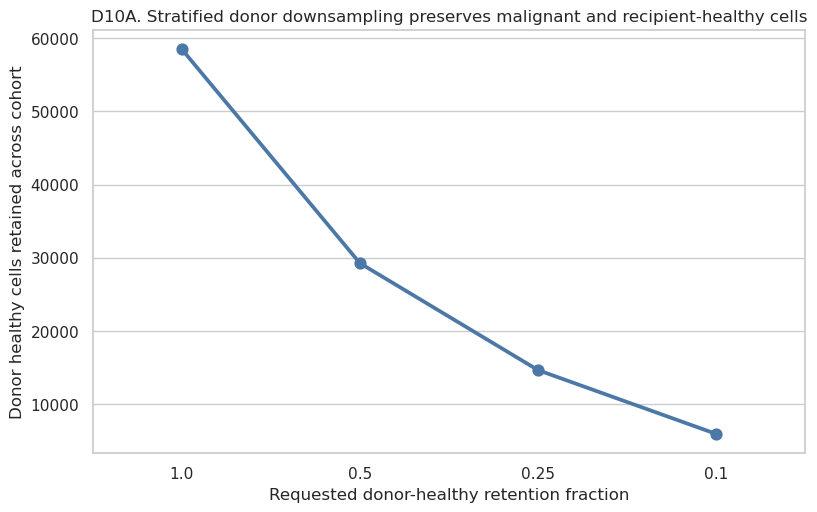

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10B_fixed_basis_ap_change_by_donor_fraction.png


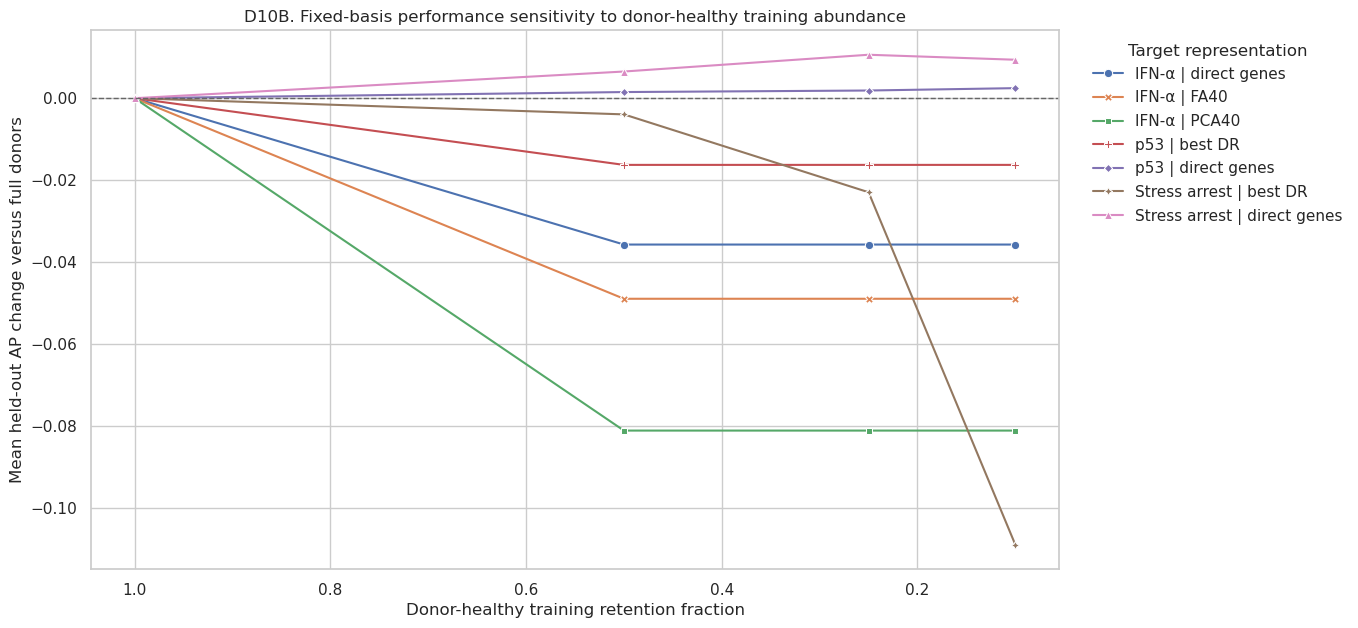

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10C_fixed_basis_patient_ap_change_25pct.png


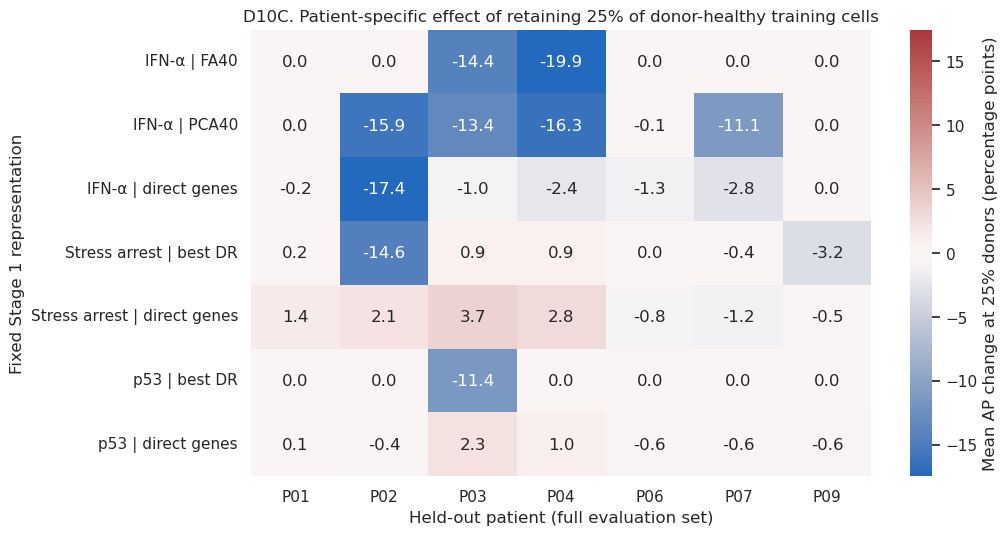

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10D_fixed_basis_factor_coefficient_stability.png


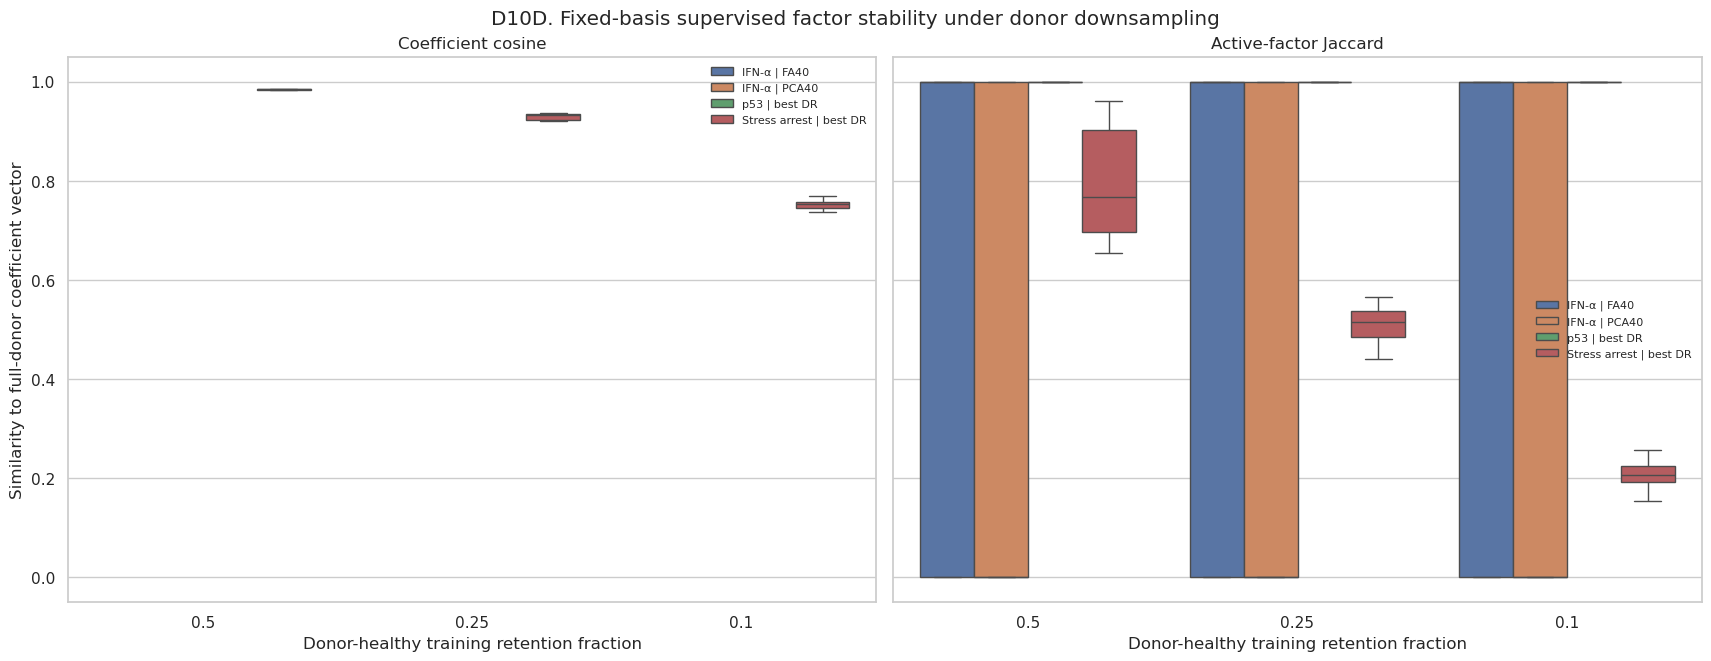

In [4]:
# D10A — retained donor counts by requested fraction.
retained_summary = (
    fixed_mask_counts.groupby(["donor_fraction", "downsample_seed"], as_index=False)
    .agg(
        donor_healthy_before=("donor_healthy_before", "sum"),
        donor_healthy_retained=("donor_healthy_retained", "sum"),
        recipient_healthy_retained=("recipient_healthy_retained", "sum"),
        malignant_retained=("malignant_retained", "sum"),
    )
)
fig, ax = plt.subplots(figsize=(9.2, 5.5))
sns.pointplot(
    data=retained_summary,
    x="donor_fraction",
    y="donor_healthy_retained",
    order=DONOR_FRACTIONS,
    errorbar="sd",
    color="#4C78A8",
    markers="o",
    linestyles="-",
    ax=ax,
)
ax.set_xlabel("Requested donor-healthy retention fraction")
ax.set_ylabel("Donor healthy cells retained across cohort")
ax.set_title("D10A. Stratified donor downsampling preserves malignant and recipient-healthy cells")
d10a_png = save_figure(fig, "D10A_retained_donor_healthy_counts")
plt.show()

# D10B — mean held-out AP change with fixed Stage 1 basis.
fixed_summary = (
    fixed_results.groupby(["target_id", "target_label", "donor_fraction"], as_index=False)
    .agg(
        mean_delta_ap=("delta_heldout_auprc_vs_full_donor", "mean"),
        median_delta_ap=("delta_heldout_auprc_vs_full_donor", "median"),
        worst_delta_ap=("delta_heldout_auprc_vs_full_donor", "min"),
        sd_delta_ap=("delta_heldout_auprc_vs_full_donor", "std"),
    )
)
fixed_summary_path = write_csv(fixed_summary, "fixed_basis_donor_downsampling_summary.csv")
fig, ax = plt.subplots(figsize=(12.5, 7.0))
sns.lineplot(
    data=fixed_summary,
    x="donor_fraction",
    y="mean_delta_ap",
    hue="target_label",
    style="target_label",
    markers=True,
    dashes=False,
    ax=ax,
)
ax.axhline(0, color="0.4", lw=1, ls="--")
ax.invert_xaxis()
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Mean held-out AP change versus full donors")
ax.set_title("D10B. Fixed-basis performance sensitivity to donor-healthy training abundance")
ax.legend(title="Target representation", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
d10b_png = save_figure(fig, "D10B_fixed_basis_ap_change_by_donor_fraction")
plt.show()

# D10C — patient-specific effect at 25% retention.
fraction_for_heatmap = 0.25
fixed_fraction_patient = (
    fixed_results.loc[fixed_results["donor_fraction"].eq(fraction_for_heatmap)]
    .groupby(["target_label", "heldout_patient"], as_index=False)
    .agg(mean_delta_ap=("delta_heldout_auprc_vs_full_donor", "mean"))
)
fixed_fraction_matrix = fixed_fraction_patient.pivot(
    index="target_label", columns="heldout_patient", values="mean_delta_ap"
).reindex(columns=SUPPORTED_PATIENTS)
vmax = max(float(np.nanpercentile(np.abs(fixed_fraction_matrix.to_numpy()), 98)), 0.005)
fig, ax = plt.subplots(figsize=(10.0, 5.8))
sns.heatmap(
    100 * fixed_fraction_matrix,
    annot=True,
    fmt=".1f",
    cmap="vlag",
    center=0,
    vmin=-100 * vmax,
    vmax=100 * vmax,
    cbar_kws={"label": "Mean AP change at 25% donors (percentage points)"},
    ax=ax,
)
ax.set_xlabel("Held-out patient (full evaluation set)")
ax.set_ylabel("Fixed Stage 1 representation")
ax.set_title("D10C. Patient-specific effect of retaining 25% of donor-healthy training cells")
d10c_png = save_figure(fig, "D10C_fixed_basis_patient_ap_change_25pct")
plt.show()

# D10D — coefficient stability for DR-factor representations.
dr_coefficient_stability = fixed_coefficient_stability.loc[
    fixed_coefficient_stability["representation_family"].eq("dr")
    & fixed_coefficient_stability["donor_fraction"].lt(1)
].copy()
stability_long = pd.concat(
    [
        dr_coefficient_stability[["target_label", "donor_fraction", "coefficient_cosine_vs_full_donor"]]
        .rename(columns={"coefficient_cosine_vs_full_donor": "stability"})
        .assign(metric="Coefficient cosine"),
        dr_coefficient_stability[["target_label", "donor_fraction", "active_feature_jaccard_vs_full_donor"]]
        .rename(columns={"active_feature_jaccard_vs_full_donor": "stability"})
        .assign(metric="Active-factor Jaccard"),
    ],
    ignore_index=True,
)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), sharey=True, constrained_layout=True)
for ax, metric in zip(axes, ["Coefficient cosine", "Active-factor Jaccard"]):
    subset = stability_long.loc[stability_long["metric"].eq(metric)]
    sns.boxplot(
        data=subset,
        x="donor_fraction",
        y="stability",
        hue="target_label",
        order=[0.5, 0.25, 0.1],
        showfliers=False,
        ax=ax,
    )
    ax.set_xlabel("Donor-healthy training retention fraction")
    ax.set_ylabel("Similarity to full-donor coefficient vector")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(metric)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("D10D. Fixed-basis supervised factor stability under donor downsampling")
d10d_png = save_figure(fig, "D10D_fixed_basis_factor_coefficient_stability")
plt.show()

## 3. IFN-α pre-DR basis sensitivity

This arm preserves the original **transductive Stage 1 scope**: each PCA40 or FA40 basis is fit once per donor-retention condition, using all retained patients, then all cells are projected. LOPO Stage 2 still excludes the held-out patient's labels and evaluates that patient's full unchanged cell set.

The fraction-1 refit must reproduce the completed IFN-α representation. Downsampled bases are aligned to that refit with a one-to-one Hungarian assignment on absolute all-cell score correlation; signs are oriented before loading-cosine calculation. Because panel scaling is refit under each retained cohort, loadings are also transformed back to the common original-gene coordinate system before comparison.

D11A is not a Stage 1-stability curve. At every fraction ≤ 0.5, every LOPO Stage 2 fit is all-zero, so held-out AP equals prevalence and mean ΔAP is exactly minus that method's full-donor mean lift. D11B/C measure the refit basis itself: scores are the cells × factors matrix, loadings are the genes × factors matrix.

In [5]:
BASIS_RESULTS_PATH = TABLE_DIR / "ifna_basis_refit_patient_metrics.csv"
BASIS_STABILITY_PATH = TABLE_DIR / "ifna_basis_refit_factor_stability.csv"
BASIS_CACHE_MANIFEST_PATH = CACHE_DIR / "ifna_basis_refit_cache_manifest.json"

basis_targets = target_manifest.loc[target_manifest["target_id"].isin(["ifna_pca40", "ifna_fa40"])].copy()
assert len(basis_targets) == 2
ifna_direct_row = target_manifest.loc[target_manifest["target_id"].eq("ifna_direct")].iloc[0]
ifna_gene_matrix, ifna_genes = load_target_features(ifna_direct_row)
assert ifna_gene_matrix.shape == (60_118, 92)

basis_cache_signature = {
    "version": 2,
    "conditions": [list(condition) for condition in condition_grid()],
    "target_records": basis_targets[["target_id", "representation_id", "penalty", "C", "l1_ratio"]].fillna("NA").to_dict("records"),
    "n_cells": len(ifna_gene_matrix),
    "n_genes": len(ifna_genes),
    "min_donor_cells_per_stratum": MIN_DONOR_CELLS_PER_STRATUM,
}
basis_cache_hit = False
if all(path.exists() for path in [BASIS_RESULTS_PATH, BASIS_STABILITY_PATH, BASIS_CACHE_MANIFEST_PATH]):
    existing_basis_manifest = json.loads(BASIS_CACHE_MANIFEST_PATH.read_text())
    basis_cache_hit = existing_basis_manifest.get("signature") == basis_cache_signature and existing_basis_manifest.get("status") == "complete"


def score_correlation_matrix(reference: np.ndarray, current: np.ndarray) -> np.ndarray:
    reference_centered = reference - reference.mean(axis=0, keepdims=True)
    current_centered = current - current.mean(axis=0, keepdims=True)
    reference_norm = np.linalg.norm(reference_centered, axis=0, keepdims=True)
    current_norm = np.linalg.norm(current_centered, axis=0, keepdims=True)
    return (reference_centered / np.maximum(reference_norm, 1e-12)).T @ (
        current_centered / np.maximum(current_norm, 1e-12)
    )


def top_gene_jaccard(left: np.ndarray, right: np.ndarray, top_n: int = 10) -> float:
    left_set = set(np.argsort(np.abs(left))[-top_n:])
    right_set = set(np.argsort(np.abs(right))[-top_n:])
    return len(left_set & right_set) / len(left_set | right_set)


if basis_cache_hit:
    basis_results = pd.read_csv(BASIS_RESULTS_PATH)
    basis_factor_stability = pd.read_csv(BASIS_STABILITY_PATH)
    print("Loaded pre-DR basis sensitivity cache")
else:
    basis_result_records = []
    basis_stability_records = []
    for _, target in basis_targets.iterrows():
        method_name = str(target["stage1_method"])
        reference_scores = None
        reference_loadings_common = None
        setting = setting_from_target(target)
        print(f"Pre-DR basis target: {target['target_label']}")
        for condition_index, (fraction, downsample_seed) in enumerate(condition_grid(), start=1):
            condition_start = time.time()
            keep_mask = donor_keep_mask(fraction, downsample_seed)
            panel_scaler = StandardScaler(with_mean=True, with_std=True)
            retained_gene_matrix = panel_scaler.fit_transform(ifna_gene_matrix[keep_mask])
            all_gene_matrix = panel_scaler.transform(ifna_gene_matrix)
            if method_name == "pca":
                basis_model = PCA(n_components=40, svd_solver="randomized", random_state=42)
            elif method_name == "fa":
                basis_model = FactorAnalysis(n_components=40, svd_method="randomized", random_state=42)
            else:
                raise ValueError(method_name)
            retained_scores = basis_model.fit_transform(retained_gene_matrix)
            all_scores = basis_model.transform(all_gene_matrix).astype(np.float32)
            # Match the Stage 1 wrapper exactly for rows used to fit the basis. For
            # randomized PCA, fit_transform scores are not numerically identical to
            # a later transform of those same rows.
            all_scores[keep_mask] = np.asarray(retained_scores, dtype=np.float32)
            loadings_standardized = np.asarray(basis_model.components_).T
            loadings_common = loadings_standardized / np.asarray(panel_scaler.scale_)[:, None]

            if reference_scores is None:
                if fraction != 1.0:
                    raise AssertionError("The first basis condition must be fraction 1")
                reference_scores = all_scores.copy()
                reference_loadings_common = loadings_common.copy()

            correlations = score_correlation_matrix(reference_scores, all_scores)
            reference_indices, current_indices = linear_sum_assignment(-np.abs(correlations))
            for reference_factor, current_factor in zip(reference_indices, current_indices):
                signed_score_correlation = float(correlations[reference_factor, current_factor])
                orientation = 1.0 if signed_score_correlation >= 0 else -1.0
                oriented_loading = orientation * loadings_common[:, current_factor]
                reference_loading = reference_loadings_common[:, reference_factor]
                basis_stability_records.append(
                    {
                        "target_id": target["target_id"],
                        "target_label": target["target_label"],
                        "stage1_method": method_name,
                        "donor_fraction": fraction,
                        "downsample_seed": downsample_seed,
                        "reference_factor": f"factor_{reference_factor + 1:03d}",
                        "current_factor": f"factor_{current_factor + 1:03d}",
                        "absolute_score_correlation": abs(signed_score_correlation),
                        "loading_cosine_common_gene_scale": cosine_similarity(reference_loading, oriented_loading),
                        "top10_gene_jaccard": top_gene_jaccard(reference_loading, oriented_loading),
                        "reference_top10_genes": ";".join(
                            np.asarray(ifna_genes)[np.argsort(np.abs(reference_loading))[-10:][::-1]]
                        ),
                        "current_top10_genes": ";".join(
                            np.asarray(ifna_genes)[np.argsort(np.abs(oriented_loading))[-10:][::-1]]
                        ),
                    }
                )

            for heldout_patient in SUPPORTED_PATIENTS:
                test_mask = cell_patients == heldout_patient
                train_mask = (cell_patients != heldout_patient) & keep_mask
                x_train, x_test = fit_preprocess_transform(all_scores[train_mask], all_scores[test_mask])
                clf = fit_model(x_train, cell_labels[train_mask], setting, MODEL_ARGS)
                probability = np.asarray(clf.predict_proba(x_test))[:, 1]
                coefficient = np.asarray(clf.coef_).ravel().astype(float)
                y_test = cell_labels[test_mask]
                prevalence = float(y_test.mean())
                basis_result_records.append(
                    {
                        **target.to_dict(),
                        "donor_fraction": fraction,
                        "downsample_seed": downsample_seed,
                        "heldout_patient": heldout_patient,
                        "n_stage1_retained_cells": int(keep_mask.sum()),
                        "n_train_cells": int(train_mask.sum()),
                        "n_test_cells_full": int(test_mask.sum()),
                        "patient_prevalence": prevalence,
                        "heldout_auprc": average_precision_score(y_test, probability),
                        "heldout_auroc": roc_auc_score(y_test, probability),
                        "heldout_lift": average_precision_score(y_test, probability) - prevalence,
                        "active_coefficient_count": int((np.abs(coefficient) > COEF_TOLERANCE).sum()),
                    }
                )
                del clf, x_train, x_test
            print(
                f"  condition {condition_index}/{len(condition_grid())}: fraction={fraction:g}, seed={downsample_seed}, "
                f"seconds={time.time() - condition_start:.1f}"
            )
            del basis_model, retained_gene_matrix, all_gene_matrix, all_scores

    basis_results = pd.DataFrame(basis_result_records)
    basis_factor_stability = pd.DataFrame(basis_stability_records)
    basis_results.to_csv(BASIS_RESULTS_PATH, index=False)
    basis_factor_stability.to_csv(BASIS_STABILITY_PATH, index=False)
    BASIS_CACHE_MANIFEST_PATH.write_text(
        json.dumps(
            {
                "status": "complete",
                "completed_utc": datetime.now(timezone.utc).isoformat(),
                "signature": basis_cache_signature,
                "rows": {"metrics": len(basis_results), "factor_stability": len(basis_factor_stability)},
            },
            indent=2,
        )
        + "\n"
    )

for path in [BASIS_RESULTS_PATH, BASIS_STABILITY_PATH]:
    if path not in GENERATED_TABLES:
        GENERATED_TABLES.append(path)

basis_reference = basis_results.loc[basis_results["donor_fraction"].eq(1.0)].copy()
basis_reference_lookup = basis_reference.set_index(["target_id", "heldout_patient"])
basis_results["reference_heldout_auprc"] = [
    basis_reference_lookup.loc[(target_id, patient_id), "heldout_auprc"]
    for target_id, patient_id in zip(basis_results["target_id"], basis_results["heldout_patient"])
]
basis_results["delta_heldout_auprc_vs_full_donor_basis"] = basis_results["heldout_auprc"] - basis_results["reference_heldout_auprc"]
basis_results.to_csv(BASIS_RESULTS_PATH, index=False)

basis_reproduction = basis_reference.merge(
    original_reference,
    on=["representation_id", "heldout_patient"],
    how="left",
    suffixes=("_refit", "_original"),
    validate="one_to_one",
)
basis_reproduction["absolute_ap_reproduction_error"] = (
    basis_reproduction["heldout_auprc_refit"] - basis_reproduction["heldout_auprc_original"]
).abs()
basis_reproduction_path = write_csv(
    basis_reproduction,
    "ifna_full_donor_basis_ap_reproduction.csv",
)

assert len(basis_results) == 2 * len(condition_grid()) * len(SUPPORTED_PATIENTS)
assert len(basis_factor_stability) == 2 * len(condition_grid()) * 40
assert basis_results.loc[basis_results["donor_fraction"].eq(1), "delta_heldout_auprc_vs_full_donor_basis"].abs().max() < 1e-12
assert basis_reproduction["absolute_ap_reproduction_error"].max() < 2e-5
print("Pre-DR basis metric rows:", len(basis_results))
print("Maximum original-AP reproduction error:", basis_reproduction["absolute_ap_reproduction_error"].max())

Loaded pre-DR basis sensitivity cache
Pre-DR basis metric rows: 140
Maximum original-AP reproduction error: 1.5130622610881606e-05


/tmp/ipykernel_1404691/663726823.py:26: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  basis_factor_stability["is_driver_factor"] = basis_factor_stability["is_driver_factor"].fillna(False).astype(bool)


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D11A_ifna_basis_refit_ap_change.png


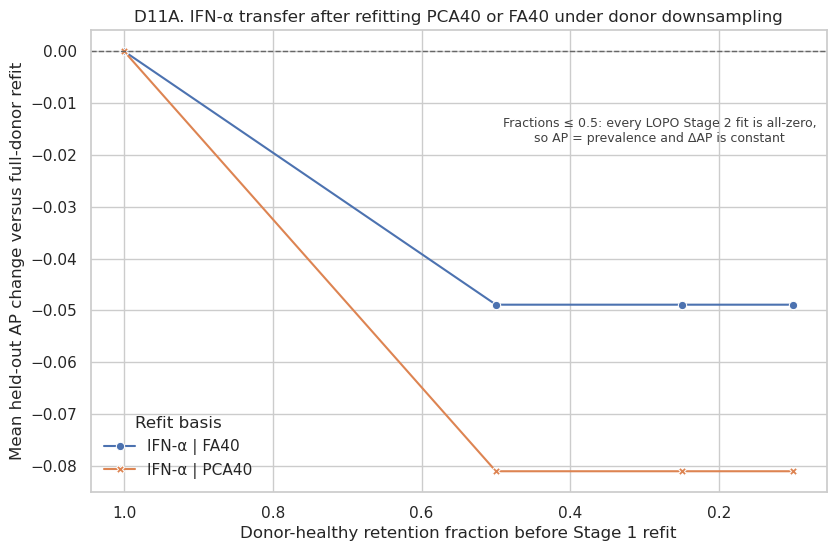

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D11B_ifna_refit_factor_score_stability.png


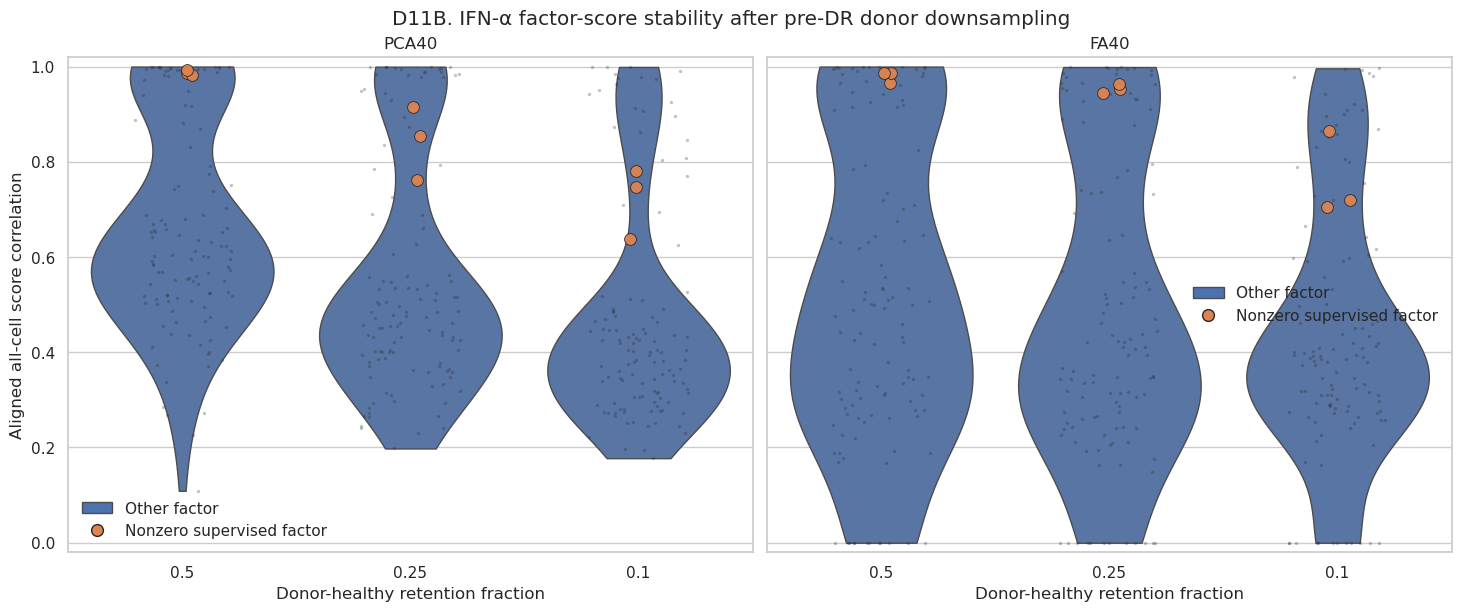

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D11C_ifna_refit_driver_loading_stability.png


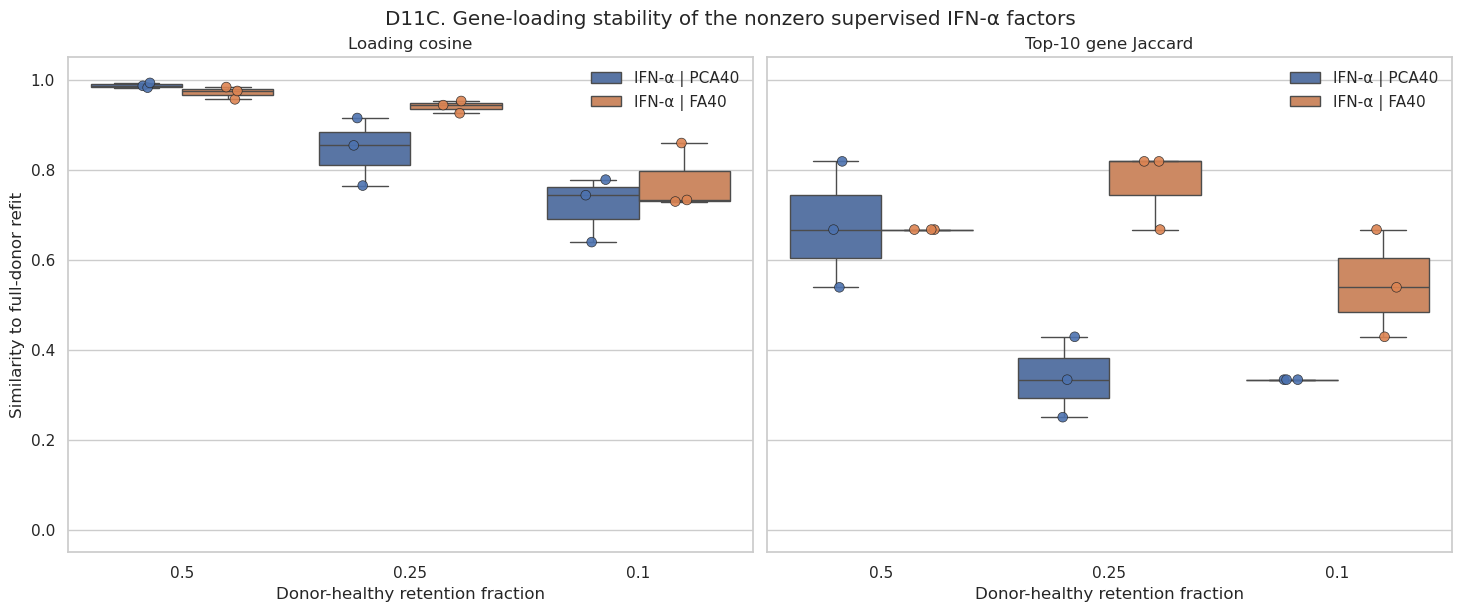

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D11D_ifna_refit_patient_ap_change_25pct.png


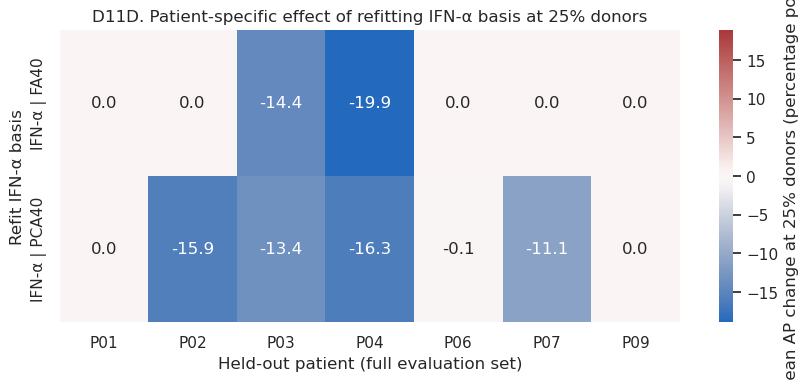

In [6]:
# Identify the five factors most used by the full-donor Stage 2 folds for each method.
ifna_reference_coefs = fixed_coefficients.loc[
    fixed_coefficients["target_id"].isin(["ifna_pca40", "ifna_fa40"])
    & fixed_coefficients["donor_fraction"].eq(1.0)
].copy()
ifna_factor_importance = (
    ifna_reference_coefs.groupby(["target_id", "feature_id"], as_index=False)
    .agg(mean_absolute_coefficient=("coefficient", lambda values: float(np.mean(np.abs(values)))))
    .sort_values(["target_id", "mean_absolute_coefficient"], ascending=[True, False])
)
# Keep only factors that were genuinely used by at least one full-donor LOPO
# model. A previous top-five summary admitted four zero-coefficient factors per
# method and therefore overstated driver stability.
ifna_driver_factors = ifna_factor_importance.loc[
    ifna_factor_importance["mean_absolute_coefficient"].gt(COEF_TOLERANCE)
].copy()
assert ifna_driver_factors.groupby("target_id").size().eq(1).all()
ifna_driver_factors["is_driver_factor"] = True
ifna_driver_path = write_csv(ifna_driver_factors, "ifna_full_donor_nonzero_supervised_factors.csv")
basis_factor_stability = basis_factor_stability.drop(columns=["is_driver_factor"], errors="ignore").merge(
    ifna_driver_factors[["target_id", "feature_id", "is_driver_factor"]].rename(columns={"feature_id": "reference_factor"}),
    on=["target_id", "reference_factor"],
    how="left",
    validate="many_to_one",
)
basis_factor_stability["is_driver_factor"] = basis_factor_stability["is_driver_factor"].fillna(False).astype(bool)
basis_factor_stability.to_csv(BASIS_STABILITY_PATH, index=False)

# D11A — performance change after refitting the basis.
basis_performance_summary = (
    basis_results.groupby(["target_id", "target_label", "stage1_method", "donor_fraction"], as_index=False)
    .agg(
        mean_delta_ap=("delta_heldout_auprc_vs_full_donor_basis", "mean"),
        median_delta_ap=("delta_heldout_auprc_vs_full_donor_basis", "median"),
        worst_delta_ap=("delta_heldout_auprc_vs_full_donor_basis", "min"),
    )
)
basis_performance_path = write_csv(basis_performance_summary, "ifna_basis_refit_performance_summary.csv")
fig, ax = plt.subplots(figsize=(9.5, 6.0))
sns.lineplot(
    data=basis_performance_summary,
    x="donor_fraction",
    y="mean_delta_ap",
    hue="target_label",
    style="target_label",
    markers=True,
    dashes=False,
    ax=ax,
)
ax.axhline(0, color="0.4", lw=1, ls="--")
ax.invert_xaxis()
ax.set_xlabel("Donor-healthy retention fraction before Stage 1 refit")
ax.set_ylabel("Mean held-out AP change versus full-donor refit")
ax.set_title("D11A. IFN-α transfer after refitting PCA40 or FA40 under donor downsampling")
ax.text(
    0.28,
    -0.018,
    "Fractions ≤ 0.5: every LOPO Stage 2 fit is all-zero,\nso AP = prevalence and ΔAP is constant",
    ha="center",
    va="bottom",
    fontsize=9,
    color="0.25",
)
ax.legend(title="Refit basis", frameon=False)
d11a_png = save_figure(fig, "D11A_ifna_basis_refit_ap_change")
plt.show()

# D11B — all-factor and supervised-driver score stability.
# Violin + strip for the 39 other factors (3 seeds × 39). The supervised driver
# has only 3 seeds, so it is drawn as points rather than a degenerate violin.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

stability_subset = basis_factor_stability.loc[basis_factor_stability["donor_fraction"].lt(1)].copy()
stability_subset["factor_role"] = np.where(
    stability_subset["is_driver_factor"], "Nonzero supervised factor", "Other factor"
)
fraction_order = [0.5, 0.25, 0.1]
palette = {
    "Other factor": sns.color_palette()[0],
    "Nonzero supervised factor": sns.color_palette()[1],
}
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.0), sharey=True, constrained_layout=True)
for ax, method_name in zip(axes, ["pca", "fa"]):
    data = stability_subset.loc[stability_subset["stage1_method"].eq(method_name)]
    other = data.loc[data["factor_role"].eq("Other factor")]
    driver = data.loc[data["factor_role"].eq("Nonzero supervised factor")]
    sns.violinplot(
        data=other,
        x="donor_fraction",
        y="absolute_score_correlation",
        order=fraction_order,
        color=palette["Other factor"],
        inner=None,
        cut=0,
        density_norm="width",
        linewidth=1.0,
        ax=ax,
    )
    sns.stripplot(
        data=other,
        x="donor_fraction",
        y="absolute_score_correlation",
        order=fraction_order,
        color="0.15",
        size=2.4,
        jitter=0.22,
        alpha=0.28,
        ax=ax,
    )
    sns.stripplot(
        data=driver,
        x="donor_fraction",
        y="absolute_score_correlation",
        order=fraction_order,
        color=palette["Nonzero supervised factor"],
        size=8.5,
        jitter=0.06,
        alpha=0.95,
        edgecolor="0.15",
        linewidth=0.6,
        ax=ax,
        zorder=3,
    )
    ax.set_xlabel("Donor-healthy retention fraction")
    ax.set_ylabel("Aligned all-cell score correlation")
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(method_name.upper() + "40")
    ax.legend(
        handles=[
            Patch(facecolor=palette["Other factor"], edgecolor="0.3", label="Other factor"),
            Line2D(
                [0],
                [0],
                marker="o",
                color="none",
                markerfacecolor=palette["Nonzero supervised factor"],
                markeredgecolor="0.15",
                markersize=8.5,
                label="Nonzero supervised factor",
            ),
        ],
        frameon=False,
    )
fig.suptitle("D11B. IFN-α factor-score stability after pre-DR donor downsampling")
d11b_png = save_figure(fig, "D11B_ifna_refit_factor_score_stability")
plt.show()

# D11C — loading and top-gene stability of supervised driver factors.
driver_stability = stability_subset.loc[stability_subset["is_driver_factor"]].copy()
driver_stability_long = pd.concat(
    [
        driver_stability[["target_label", "donor_fraction", "loading_cosine_common_gene_scale"]]
        .rename(columns={"loading_cosine_common_gene_scale": "stability"})
        .assign(metric="Loading cosine"),
        driver_stability[["target_label", "donor_fraction", "top10_gene_jaccard"]]
        .rename(columns={"top10_gene_jaccard": "stability"})
        .assign(metric="Top-10 gene Jaccard"),
    ],
    ignore_index=True,
)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.0), sharey=True, constrained_layout=True)
for ax, metric in zip(axes, ["Loading cosine", "Top-10 gene Jaccard"]):
    sns.boxplot(
        data=driver_stability_long.loc[driver_stability_long["metric"].eq(metric)],
        x="donor_fraction",
        y="stability",
        hue="target_label",
        order=[0.5, 0.25, 0.1],
        showfliers=False,
        ax=ax,
    )
    sns.stripplot(
        data=driver_stability_long.loc[driver_stability_long["metric"].eq(metric)],
        x="donor_fraction",
        y="stability",
        hue="target_label",
        order=[0.5, 0.25, 0.1],
        dodge=True,
        jitter=0.12,
        size=7,
        alpha=0.9,
        edgecolor="0.15",
        linewidth=0.5,
        ax=ax,
        legend=False,
    )
    ax.set_xlabel("Donor-healthy retention fraction")
    ax.set_ylabel("Similarity to full-donor refit")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(metric)
    ax.legend(frameon=False)
fig.suptitle("D11C. Gene-loading stability of the nonzero supervised IFN-α factors")
d11c_png = save_figure(fig, "D11C_ifna_refit_driver_loading_stability")
plt.show()

# D11D — patient-specific AP response at 25% donors.
basis_25_patient = (
    basis_results.loc[basis_results["donor_fraction"].eq(0.25)]
    .groupby(["target_label", "heldout_patient"], as_index=False)
    .agg(mean_delta_ap=("delta_heldout_auprc_vs_full_donor_basis", "mean"))
)
basis_25_matrix = basis_25_patient.pivot(index="target_label", columns="heldout_patient", values="mean_delta_ap").reindex(columns=SUPPORTED_PATIENTS)
vmax = max(float(np.nanpercentile(np.abs(basis_25_matrix.to_numpy()), 98)), 0.005)
fig, ax = plt.subplots(figsize=(10.0, 3.8))
sns.heatmap(
    100 * basis_25_matrix,
    annot=True,
    fmt=".1f",
    cmap="vlag",
    center=0,
    vmin=-100 * vmax,
    vmax=100 * vmax,
    cbar_kws={"label": "Mean AP change at 25% donors (percentage points)"},
    ax=ax,
)
ax.set_xlabel("Held-out patient (full evaluation set)")
ax.set_ylabel("Refit IFN-α basis")
ax.set_title("D11D. Patient-specific effect of refitting IFN-α basis at 25% donors")
d11d_png = save_figure(fig, "D11D_ifna_refit_patient_ap_change_25pct")
plt.show()

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10E_fixed_basis_zero_coefficient_collapse.png


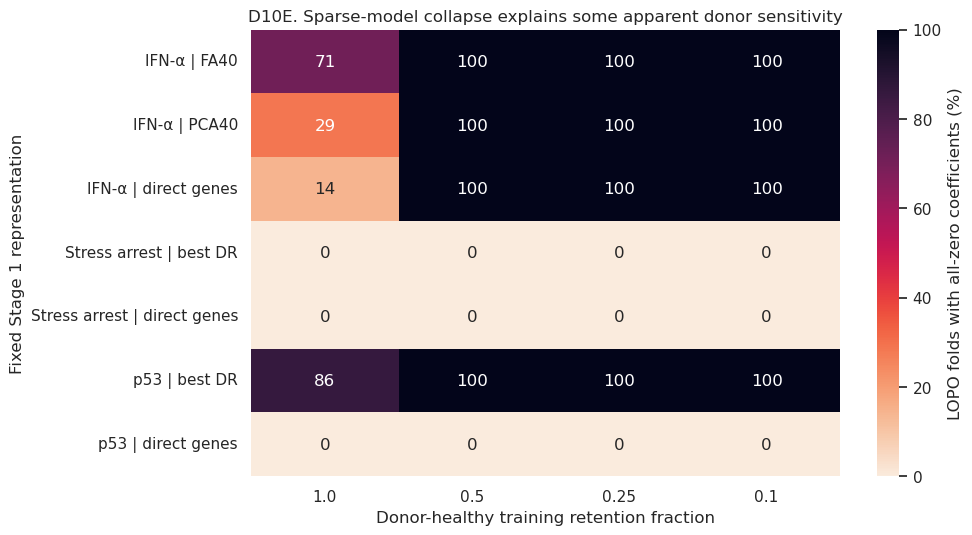

In [7]:
# D10E — diagnose regularization collapse rather than mislabel it as donor biology.
fixed_results["zero_coefficient_solution"] = fixed_results["active_coefficient_count"].eq(0)
coefficient_collapse_summary = (
    fixed_results.groupby(["target_id", "target_label", "donor_fraction"], as_index=False)
    .agg(
        zero_solution_fraction=("zero_coefficient_solution", "mean"),
        median_active_coefficients=("active_coefficient_count", "median"),
    )
)
coefficient_collapse_path = write_csv(
    coefficient_collapse_summary,
    "fixed_basis_regularization_collapse_summary.csv",
)
collapse_matrix = coefficient_collapse_summary.pivot(
    index="target_label", columns="donor_fraction", values="zero_solution_fraction"
).reindex(columns=DONOR_FRACTIONS)
fig, ax = plt.subplots(figsize=(9.5, 5.8))
sns.heatmap(
    100 * collapse_matrix,
    annot=True,
    fmt=".0f",
    cmap="rocket_r",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "LOPO folds with all-zero coefficients (%)"},
    ax=ax,
)
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Fixed Stage 1 representation")
ax.set_title("D10E. Sparse-model collapse explains some apparent donor sensitivity")
d10e_png = save_figure(fig, "D10E_fixed_basis_zero_coefficient_collapse")
plt.show()

Each D10E cell is a percent of LOPO fits.
Fraction 1.0 = 7 patients × 1 seed. Downsampled fractions = 7 patients × 3 seeds.


,target_label,donor_fraction,n_fits,n_zero_fits,zero_solution_fraction,median_active_coefficients,n_features,mean_heldout_lift
7,IFN-α | FA40,1.00,7,5,0.714286,0.0,40,0.048912
5,IFN-α | FA40,0.25,21,21,1.000000,0.0,40,0.000000
11,IFN-α | PCA40,1.00,7,2,0.285714,1.0,40,0.081062
9,IFN-α | PCA40,0.25,21,21,1.000000,0.0,40,0.000000
3,IFN-α | direct genes,1.00,7,1,0.142857,1.0,92,0.035690
1,IFN-α | direct genes,0.25,21,21,1.000000,0.0,92,0.000000
23,Stress arrest | best DR,1.00,7,0,0.000000,31.0,40,0.196715
21,Stress arrest | best DR,0.25,21,0,0.000000,16.0,40,0.173782
27,Stress arrest | direct genes,1.00,7,0,0.000000,685.0,685,0.193907
25,Stress arrest | direct genes,0.25,21,0,0.000000,685.0,685,0.204509


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10E2_collapse_and_active_coefficient_count.png


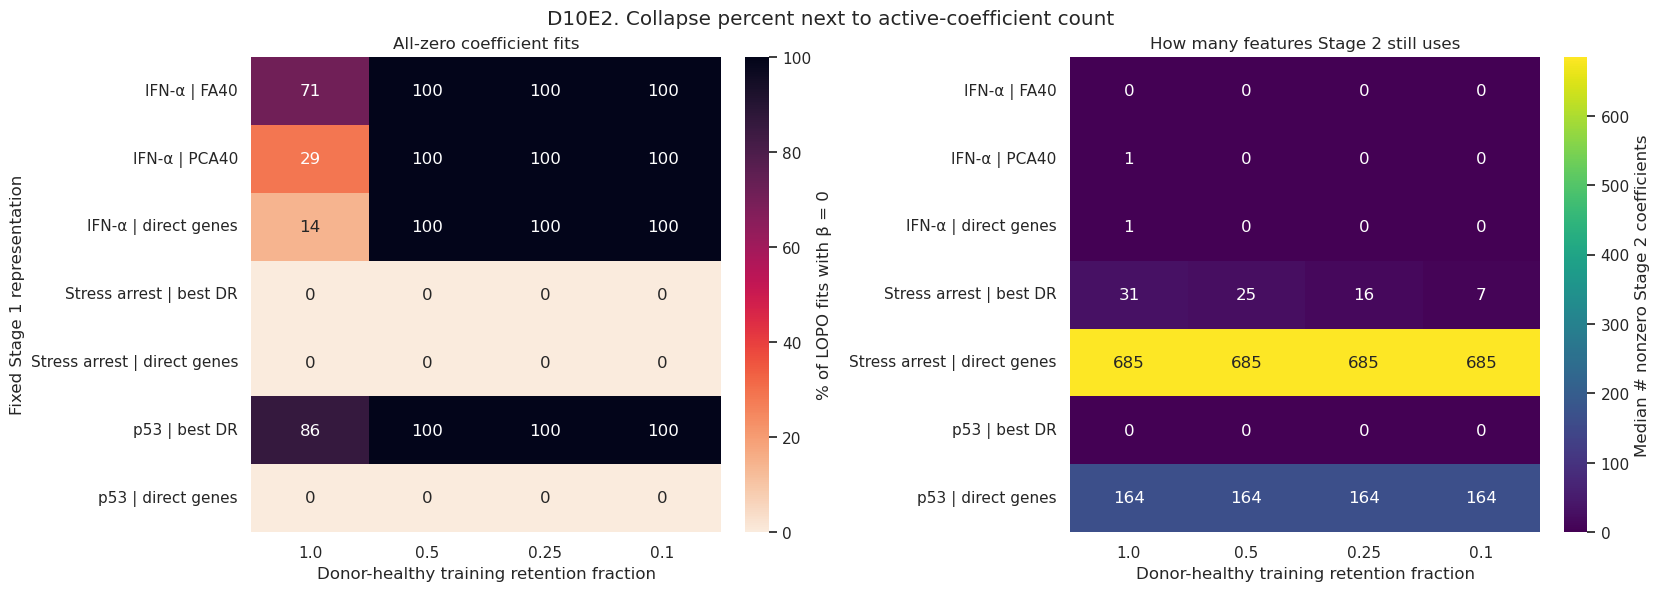

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10F_fixed_basis_active_coefficient_count.png


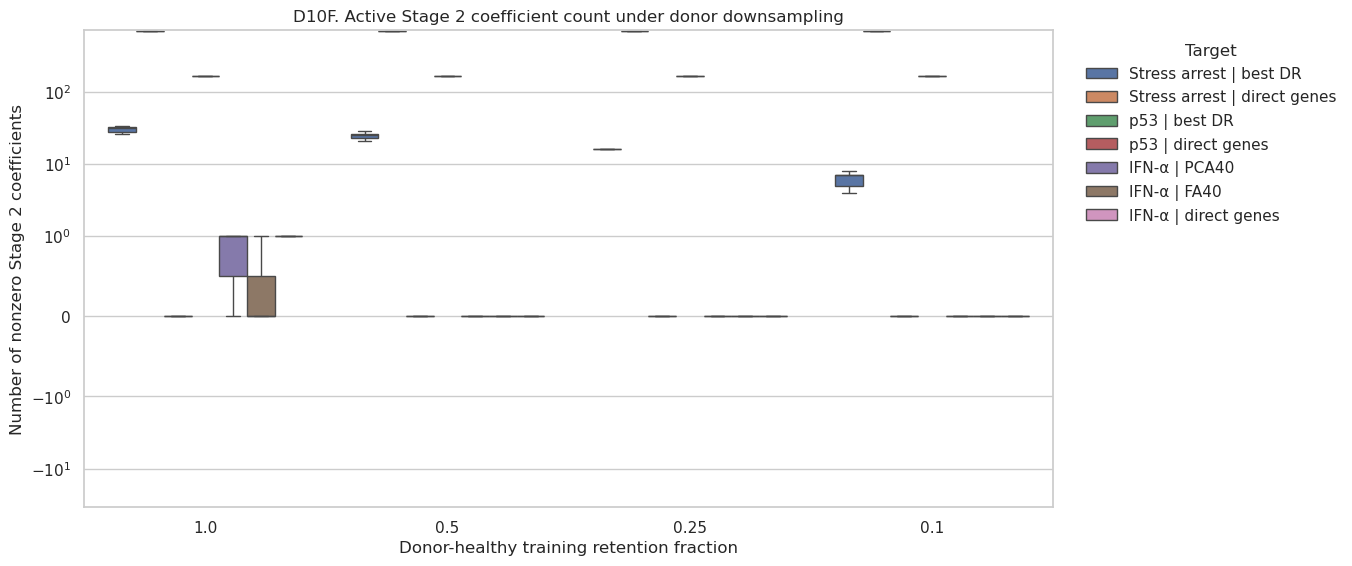

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10G_fixed_basis_patient_active_coefficient_count.png


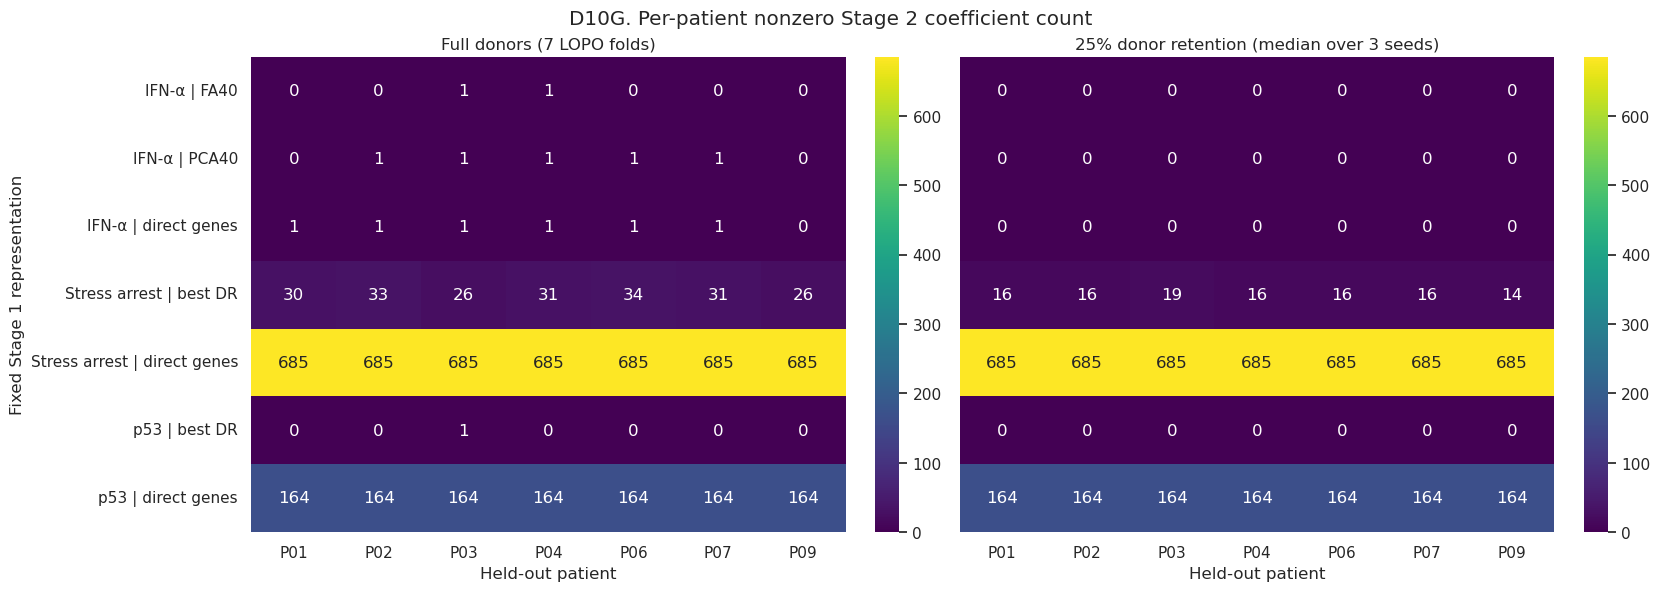

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10H_fixed_basis_mean_lift_by_donor_fraction.png


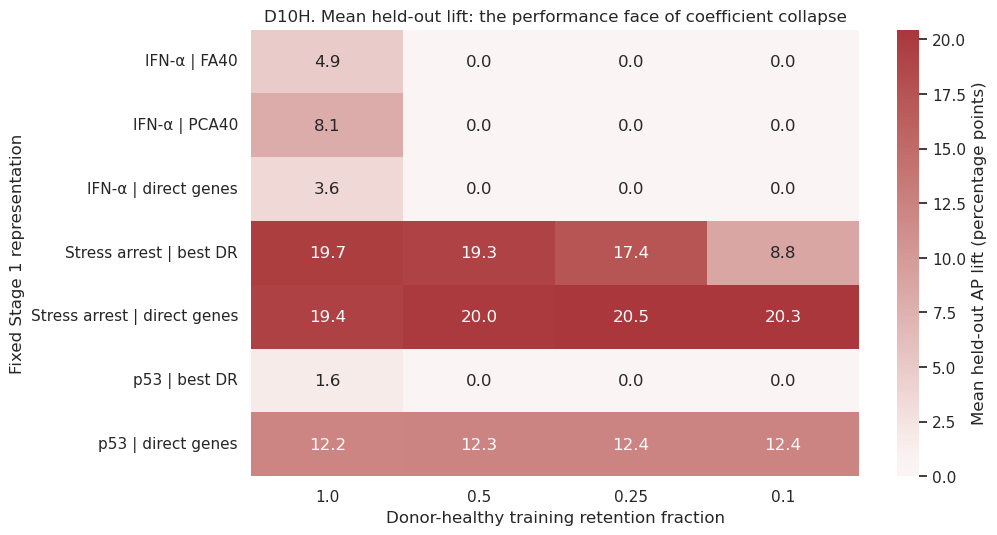

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v1/D10A2_stratum_realized_retention_25pct.png


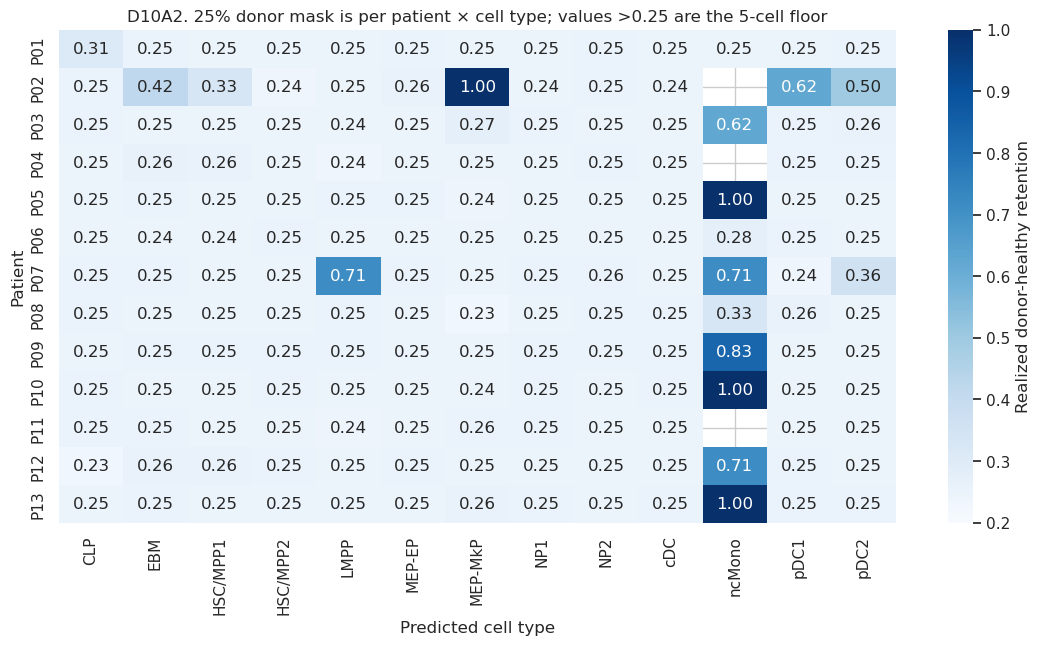

Strata at 25% seed 42: 166 ; floor-bound (realized > 0.26): 19


In [8]:
# Companions to D10E: coefficient counts, per-patient grid, lift, and stratum QC.
# Fraction 1.0 has 7 LOPO folds (7 patients × 1 seed). Downsampled fractions have 21
# folds (7 patients × 3 mask seeds). 71% for IFN-α FA40 at 1.0 is 5/7 original folds
# already all-zero at the globally selected C.
if "n_fits" not in coefficient_collapse_summary.columns:
    coefficient_collapse_summary = (
        fixed_results.groupby(["target_id", "target_label", "donor_fraction"], as_index=False)
        .agg(
            n_fits=("zero_coefficient_solution", "size"),
            n_zero_fits=("zero_coefficient_solution", "sum"),
            zero_solution_fraction=("zero_coefficient_solution", "mean"),
            median_active_coefficients=("active_coefficient_count", "median"),
            mean_heldout_lift=("heldout_lift", "mean"),
        )
    )
    n_features_lookup = target_manifest.set_index("target_label")["n_features"]
    coefficient_collapse_summary["n_features"] = coefficient_collapse_summary["target_label"].map(n_features_lookup)
    coefficient_collapse_path = write_csv(
        coefficient_collapse_summary,
        "fixed_basis_regularization_collapse_summary.csv",
    )

print("Each D10E cell is a percent of LOPO fits.")
print("Fraction 1.0 = 7 patients × 1 seed. Downsampled fractions = 7 patients × 3 seeds.")
display(
    coefficient_collapse_summary.loc[
        coefficient_collapse_summary["donor_fraction"].isin([1.0, 0.25]),
        [
            "target_label",
            "donor_fraction",
            "n_fits",
            "n_zero_fits",
            "zero_solution_fraction",
            "median_active_coefficients",
            "n_features",
            "mean_heldout_lift",
        ],
    ].sort_values(["target_label", "donor_fraction"], ascending=[True, False])
)

active_matrix = coefficient_collapse_summary.pivot(
    index="target_label", columns="donor_fraction", values="median_active_coefficients"
).reindex(columns=DONOR_FRACTIONS)
lift_matrix = coefficient_collapse_summary.pivot(
    index="target_label", columns="donor_fraction", values="mean_heldout_lift"
).reindex(columns=DONOR_FRACTIONS)
collapse_matrix = coefficient_collapse_summary.pivot(
    index="target_label", columns="donor_fraction", values="zero_solution_fraction"
).reindex(columns=DONOR_FRACTIONS)

fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.8), constrained_layout=True)
sns.heatmap(
    100 * collapse_matrix,
    annot=True,
    fmt=".0f",
    cmap="rocket_r",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "% of LOPO fits with β = 0"},
    ax=axes[0],
)
axes[0].set_xlabel("Donor-healthy training retention fraction")
axes[0].set_ylabel("Fixed Stage 1 representation")
axes[0].set_title("All-zero coefficient fits")
sns.heatmap(
    active_matrix,
    annot=True,
    fmt=".0f",
    cmap="viridis",
    cbar_kws={"label": "Median # nonzero Stage 2 coefficients"},
    ax=axes[1],
)
axes[1].set_xlabel("Donor-healthy training retention fraction")
axes[1].set_ylabel("")
axes[1].set_title("How many features Stage 2 still uses")
fig.suptitle("D10E2. Collapse percent next to active-coefficient count")
d10e2_png = save_figure(fig, "D10E2_collapse_and_active_coefficient_count")
plt.show()

fig, ax = plt.subplots(figsize=(12.5, 6.2))
sns.boxplot(
    data=fixed_results,
    x="donor_fraction",
    y="active_coefficient_count",
    hue="target_label",
    order=DONOR_FRACTIONS,
    showfliers=False,
    ax=ax,
)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Number of nonzero Stage 2 coefficients")
ax.set_title("D10F. Active Stage 2 coefficient count under donor downsampling")
ax.legend(title="Target", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
d10f_png = save_figure(fig, "D10F_fixed_basis_active_coefficient_count")
plt.show()

patient_active = (
    fixed_results.loc[fixed_results["donor_fraction"].isin([1.0, 0.25])]
    .groupby(["target_label", "heldout_patient", "donor_fraction"], as_index=False)
    .agg(median_active=("active_coefficient_count", "median"))
)
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.8), constrained_layout=True, sharey=True)
for ax, fraction, title in zip(
    axes,
    [1.0, 0.25],
    ["Full donors (7 LOPO folds)", "25% donor retention (median over 3 seeds)"],
):
    matrix = (
        patient_active.loc[patient_active["donor_fraction"].eq(fraction)]
        .pivot(index="target_label", columns="heldout_patient", values="median_active")
        .reindex(columns=SUPPORTED_PATIENTS)
    )
    sns.heatmap(matrix, annot=True, fmt=".0f", cmap="viridis", ax=ax)
    ax.set_xlabel("Held-out patient")
    ax.set_title(title)
axes[0].set_ylabel("Fixed Stage 1 representation")
axes[1].set_ylabel("")
fig.suptitle("D10G. Per-patient nonzero Stage 2 coefficient count")
d10g_png = save_figure(fig, "D10G_fixed_basis_patient_active_coefficient_count")
plt.show()

fig, ax = plt.subplots(figsize=(9.8, 5.8))
sns.heatmap(
    100 * lift_matrix,
    annot=True,
    fmt=".1f",
    cmap="vlag",
    center=0,
    cbar_kws={"label": "Mean held-out AP lift (percentage points)"},
    ax=ax,
)
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Fixed Stage 1 representation")
ax.set_title("D10H. Mean held-out lift: the performance face of coefficient collapse")
d10h_png = save_figure(fig, "D10H_fixed_basis_mean_lift_by_donor_fraction")
plt.show()

keep_25 = donor_keep_mask(0.25, 42)
donor_index = np.flatnonzero(donor_healthy)
stratum_qc = mrd_obs.iloc[donor_index][["patient", "predicted.annotation"]].copy()
stratum_qc["retained"] = keep_25[donor_index]
stratum_qc = (
    stratum_qc.groupby(["patient", "predicted.annotation"], as_index=False)
    .agg(n_donor=("retained", "size"), n_kept=("retained", "sum"))
)
stratum_qc["realized_fraction"] = stratum_qc["n_kept"] / stratum_qc["n_donor"]
stratum_qc_path = write_csv(stratum_qc, "donor_sensitivity_stratum_realized_fraction_25pct_seed42.csv")
stratum_matrix = stratum_qc.pivot(
    index="patient", columns="predicted.annotation", values="realized_fraction"
)
fig, ax = plt.subplots(figsize=(13.5, 6.4))
sns.heatmap(
    stratum_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0.2,
    vmax=1.0,
    cbar_kws={"label": "Realized donor-healthy retention"},
    ax=ax,
)
ax.set_xlabel("Predicted cell type")
ax.set_ylabel("Patient")
ax.set_title("D10A2. 25% donor mask is per patient × cell type; values >0.25 are the 5-cell floor")
d10a2_png = save_figure(fig, "D10A2_stratum_realized_retention_25pct")
plt.show()
print(
    "Strata at 25% seed 42:",
    len(stratum_qc),
    "; floor-bound (realized > 0.26):",
    int((stratum_qc["realized_fraction"] > 0.26).sum()),
)


## 4. Interpretation, plot contracts, and artifact ledger

This is a sensitivity analysis, not a causal donor-origin test. A performance change can arise from (i) less healthy-cell support, (ii) a shifted Stage 1 basis, or (iii) a fixed regularization setting crossing from a sparse nonzero solution to the all-zero solution. D10E makes mechanism (iii) explicit. Therefore, an AP loss accompanied by coefficient collapse is **not** interpreted as evidence that the model learned donor identity.

Descriptive review guides used below (not inferential cutoffs): AP change of 0.02, aligned score/loading similarity of 0.90, and top-10 gene Jaccard of 0.50.

In [9]:
AP_MATERIALITY_GUIDE = 0.02
FACTOR_SIMILARITY_GUIDE = 0.90
TOP_GENE_JACCARD_GUIDE = 0.50

basis_factor_summary = (
    basis_factor_stability.groupby(
        ["target_id", "target_label", "stage1_method", "donor_fraction", "is_driver_factor"],
        as_index=False,
    )
    .agg(
        median_score_correlation=("absolute_score_correlation", "median"),
        p20_score_correlation=("absolute_score_correlation", lambda values: float(np.quantile(values, 0.2))),
        median_loading_cosine=("loading_cosine_common_gene_scale", "median"),
        p20_loading_cosine=("loading_cosine_common_gene_scale", lambda values: float(np.quantile(values, 0.2))),
        median_top10_gene_jaccard=("top10_gene_jaccard", "median"),
        p20_top10_gene_jaccard=("top10_gene_jaccard", lambda values: float(np.quantile(values, 0.2))),
        n_reference_factors=("reference_factor", "nunique"),
        n_factor_seed_rows=("reference_factor", "size"),
    )
)
basis_factor_summary_path = write_csv(
    basis_factor_summary,
    "ifna_basis_refit_factor_stability_summary.csv",
)


def plot_contract(
    plot_id: str,
    decision: str,
    comparison: str,
    held_fixed: str,
    denominator: str,
    uncertainty: str,
    success: str,
    failure: str,
    caveat: str,
) -> dict[str, str]:
    return {
        "plot_id": plot_id,
        "status": "diagnostic_not_manuscript_ready",
        "decision": decision,
        "comparison": comparison,
        "held_fixed": held_fixed,
        "denominator_or_unit": denominator,
        "uncertainty": uncertainty,
        "success_pattern": success,
        "failure_pattern": failure,
        "primary_caveat": caveat,
    }


plot_contracts = pd.DataFrame(
    [
        plot_contract(
            "D10A",
            "Verify that the intervention changes only donor-healthy support.",
            "Requested donor fraction versus actual retained donor cells.",
            "All malignant and recipient-healthy cells; patient × predicted-cell-type stratification.",
            "Cell count across the exact 60,118-cell cohort.",
            "Three mask seeds for fractions below 1.",
            "Monotone retained counts with invariant malignant/recipient counts.",
            "Non-target cells removed or requested fractions not achieved.",
            "Small strata retain at least five donor cells, so realized fractions differ slightly.",
        ),
        plot_contract(
            "D10B",
            "Assess supervised-model sensitivity to donor-healthy training abundance.",
            "Mean full-held-out-patient AP change versus the fraction-1 refit.",
            "Stage 1 scores, global regularization, class weighting, full held-out evaluation.",
            "AP difference; averaged descriptively over seven patients and three mask seeds.",
            "Patient and mask-seed variation; no inferential interval.",
            "Changes remain near zero as donors are reduced.",
            "Large negative changes, especially before extreme downsampling.",
            "A fixed sparse regularization can collapse; inspect D10E before biological attribution.",
        ),
        plot_contract(
            "D10C",
            "Locate patient-specific fixed-basis sensitivity at a moderate intervention.",
            "Mean AP change at 25% donors for each target × held-out patient.",
            "Full held-out cells and prevalence; three mask seeds.",
            "AP percentage-point difference from fraction 1.",
            "Mean across three masks; individual patients are not replicates for inference.",
            "No concentrated patient-specific losses.",
            "Large losses localized to specific held-out patients.",
            "Differences can reflect sparse-model collapse rather than donor-recipient biology.",
        ),
        plot_contract(
            "D10D",
            "Assess whether fixed-basis supervised factor use changes.",
            "Coefficient cosine and active-factor Jaccard versus fraction-1 folds.",
            "Same representation, regularization, held-out patient, and evaluation set.",
            "Similarity in [0,1] where 1 is identical up to magnitude for cosine.",
            "Distributions across patients and mask seeds.",
            "High cosine and Jaccard through moderate downsampling.",
            "Low similarity or zero active-factor overlap.",
            "All-zero solutions make factor selection uninformative; inspect D10E.",
        ),
        plot_contract(
            "D10E",
            "Separate regularization-path failure from donor-origin sensitivity.",
            "Fraction of LOPO fits with all-zero coefficients by target and donor fraction.",
            "Selected global C/penalty and Stage 1 basis.",
            "Percent of seven-patient × seed fits.",
            "Descriptive fold/seed frequency.",
            "Nonzero models remain estimable across fractions.",
            "Abrupt all-zero transition after any donor reduction.",
            "Collapse diagnoses a fixed-C pathology; it does not identify the biological cause.",
        ),
        plot_contract(
            "D10E2",
            "Show how many Stage 2 coefficients remain when D10E reports collapse.",
            "Median nonzero coefficient count beside the all-zero fold percent.",
            "Same fits as D10E; 7 folds at fraction 1.0 and 21 folds otherwise.",
            "Count of |β_j| > 1e-8.",
            "Median over patients and mask seeds.",
            "Nonzero counts persist under donor reduction.",
            "Counts drop to zero for L1/elastic-net targets after any donor cut.",
            "L2 direct-gene models stay fully dense and should not be compared on the same linear count scale.",
        ),
        plot_contract(
            "D10F",
            "Display the full distribution of active Stage 2 coefficient counts.",
            "Boxplots of nonzero coefficient count by donor fraction and target.",
            "Fixed Stage 1, frozen C, LOPO training masks.",
            "Active feature count on a symlog axis.",
            "Patients and three mask seeds.",
            "Stress-arrest DR shrinks gradually; L2 stays dense.",
            "Sparse IFN-α/p53 models jump from 0–1 coefficients to zero.",
            "A log axis is required because 0–1 and 685 cannot share a linear scale.",
        ),
        plot_contract(
            "D10G",
            "Recover the per-patient LOPO pattern behind D10E percentages.",
            "Nonzero coefficient count by held-out patient at 100% versus 25% donors.",
            "Globally selected C applied independently to each LOPO fold.",
            "Median active count over seeds.",
            "Seven supported patients; three seeds at 25%.",
            "The same patients remain nonzero after downsampling.",
            "Patients with one active factor at 100% go to zero at 25%.",
            "C is not reselected per patient; 0 versus 1 is the L1 solution at one global C.",
        ),
        plot_contract(
            "D10H",
            "Attach held-out lift to the collapse heatmap.",
            "Mean AP lift by target and donor fraction.",
            "Full held-out evaluation; frozen regularization.",
            "AP minus prevalence, averaged over folds/seeds.",
            "Descriptive mean only.",
            "Lift remains near the fraction-1 value.",
            "Lift falls to 0 exactly where D10E is 100% all-zero.",
            "Lift = 0 is AP = prevalence, not AP = 0.",
        ),
        plot_contract(
            "D10A2",
            "Show that donor downsampling is applied inside every patient × cell-type stratum.",
            "Realized retention fraction at 25% donors, seed 42.",
            "MIN_DONOR_CELLS_PER_STRATUM = 5; malignant and recipient-healthy cells are never dropped.",
            "Kept / original donor-healthy cells in that stratum.",
            "One representative mask seed.",
            "Most large strata sit at 0.25.",
            "Small strata sit above 0.25 or at 1.0 because of the 5-cell floor.",
            "There is no size threshold that skips a cell type; every stratum is downsampled unless n ≤ 5.",
        ),
        plot_contract(
            "D11A",
            "Assess combined IFN-α basis and supervised-transfer sensitivity.",
            "PCA40/FA40 refit at each donor fraction versus its fraction-1 refit.",
            "Panel genes, K=40, Stage 1 seed, global Stage 2 regularization, full held-out evaluation.",
            "Mean AP difference across seven patients and three mask seeds.",
            "Patient and seed variation; no inferential interval.",
            "Near-zero AP change with stable factors.",
            "Material AP loss before extreme downsampling.",
            "AP can still be dominated by all-zero Stage 2 solutions; use D11B/C for basis evidence.",
        ),
        plot_contract(
            "D11B",
            "Determine whether IFN-α factor scores move when donor abundance changes before DR.",
            "Hungarian-aligned refit factors versus the fraction-1 basis.",
            "Same 92 genes, K=40, Stage 1 seed, and all-cell projection set.",
            "Absolute all-cell score correlation.",
            "Distributions over 40 factors, three seeds, and driver/non-driver strata.",
            "Driver factors retain correlation at or above 0.90.",
            "Driver factors lose one-to-one score correspondence.",
            "Transductive alignment is descriptive and does not establish external reproducibility.",
        ),
        plot_contract(
            "D11C",
            "Assess biological-gene grounding stability of supervised IFN-α factors.",
            "Aligned driver loadings versus fraction-1 in common gene coordinates.",
            "Factors with nonzero mean absolute full-donor Stage 2 coefficient; one factor per method here.",
            "Loading cosine and top-10 absolute-loading gene Jaccard.",
            "Distributions across driver factors and mask seeds.",
            "Loading cosine ≥0.90 and gene Jaccard ≥0.50 at moderate downsampling.",
            "Low loading similarity or replacement of top genes.",
            "Top-five selection is conditioned on the full-donor supervised model.",
        ),
        plot_contract(
            "D11D",
            "Locate patient-specific transfer changes after IFN-α basis refit.",
            "Mean AP change at 25% donors for PCA40 and FA40 by held-out patient.",
            "Full held-out evaluation, prevalence, K, and regularization.",
            "AP percentage-point difference from each method's fraction-1 refit.",
            "Mean over three masks; seven patients only.",
            "No selective degradation of P02/P07 relative to P03/P04.",
            "P02/P07-specific degradation under refit.",
            "Sparse Stage 2 collapse must be separated from factor movement.",
        ),
    ]
)
plot_contracts_path = write_csv(plot_contracts, "donor_sensitivity_plot_contracts.csv")

fixed_25 = fixed_summary.loc[fixed_summary["donor_fraction"].eq(0.25)].set_index("target_id")
collapse_25 = coefficient_collapse_summary.loc[
    coefficient_collapse_summary["donor_fraction"].eq(0.25)
].set_index("target_id")
basis_25 = basis_performance_summary.loc[
    basis_performance_summary["donor_fraction"].eq(0.25)
].set_index("target_id")
driver_factor_25 = basis_factor_summary.loc[
    basis_factor_summary["donor_fraction"].eq(0.25)
    & basis_factor_summary["is_driver_factor"]
].set_index("target_id")

findings_lines = [
    "# Old34 donor-downsampling sensitivity findings",
    "",
    f"Generated: {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Design",
    "",
    f"- Exact binary MRD/CITE cohort: {len(mrd_obs):,} cells; {int(donor_healthy.sum()):,} donor healthy, {int(recipient_healthy.sum()):,} recipient healthy, {int(cell_labels.sum()):,} malignant.",
    f"- Fixed-basis arm: {len(target_manifest)} targets × {len(SUPPORTED_PATIENTS)} held-out patients × {len(condition_grid())} donor-mask conditions = {len(fixed_results):,} fits.",
    f"- Pre-DR arm: IFN-α PCA40 and FA40 × {len(condition_grid())} transductive basis refits; {len(basis_results):,} full-held-out Stage 2 evaluations.",
    "- Fractions below 1 use three deterministic patient × predicted-cell-type-stratified masks; malignant and recipient-healthy cells are never removed.",
    "",
    "## Fixed Stage 1 basis: mean AP change at 25% donor retention",
    "",
]
for target_id, row in fixed_25.iterrows():
    findings_lines.append(
        f"- {row['target_label']}: {row['mean_delta_ap']:+.4f} mean AP; "
        f"{row['worst_delta_ap']:+.4f} worst patient/seed; "
        f"{100 * collapse_25.loc[target_id, 'zero_solution_fraction']:.0f}% all-zero Stage 2 fits."
    )
findings_lines.extend(
    [
        "",
        "## IFN-α pre-DR basis refit at 25% donor retention",
        "",
    ]
)
for target_id, row in basis_25.iterrows():
    factor_row = driver_factor_25.loc[target_id]
    findings_lines.append(
        f"- {row['target_label']}: {row['mean_delta_ap']:+.4f} mean AP; driver-factor median "
        f"score correlation {factor_row['median_score_correlation']:.3f}, loading cosine "
        f"{factor_row['median_loading_cosine']:.3f}, top-10 gene Jaccard "
        f"{factor_row['median_top10_gene_jaccard']:.3f}."
    )
findings_lines.extend(
    [
        "",
        "## Interpretation boundary",
        "",
        "- Any AP loss accompanied by an all-zero coefficient transition is a fixed-regularization pathology and cannot be attributed to donor identity.",
        "- Direct-gene L2 targets provide the cleanest supervised abundance sensitivity because they do not cross an L1/elastic-net zero boundary as readily.",
        "- Factor-score and loading stability are the relevant evidence for whether donor abundance materially changes the Stage 1 biological representation.",
        "- This targeted sensitivity does not establish donor-versus-recipient invariance; recipient-healthy support is too sparse for a balanced origin-stratified test.",
    ]
)
findings_path = TABLE_DIR / "donor_sensitivity_findings.md"
findings_path.write_text("\n".join(findings_lines) + "\n")
GENERATED_TABLES.append(findings_path)


def source_signature(path: Path) -> dict[str, object]:
    stat = path.stat()
    return {
        "path": str(path),
        "size_bytes": stat.st_size,
        "mtime_utc": datetime.fromtimestamp(stat.st_mtime, tz=timezone.utc).isoformat(),
    }


manifest = {
    "analysis_id": "old34_donor_sensitivity_v1",
    "experiment_id": EXPERIMENT_ID,
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "producer_notebook": str(Path("scripts/mrd_stage0_2/notebooks/stage0_2/stage2_old34_donor_downsampling_sensitivity.ipynb")),
    "scope": {
        "fixed_basis_targets": target_manifest["target_id"].tolist(),
        "basis_refit_targets": basis_targets["target_id"].tolist(),
        "supported_patients": SUPPORTED_PATIENTS,
        "donor_fractions": DONOR_FRACTIONS,
        "downsample_seeds": DOWNSAMPLE_SEEDS,
        "conditions": [list(condition) for condition in condition_grid()],
        "heldout_evaluation": "full_unchanged_patient",
        "stage1_refit_scope": "transductive_all_retained_patients",
        "stratification": ["patient", "predicted.annotation"],
        "preserved_cells": ["all_malignant", "all_recipient_healthy"],
    },
    "review_guides": {
        "absolute_ap_change": AP_MATERIALITY_GUIDE,
        "factor_score_or_loading_similarity": FACTOR_SIMILARITY_GUIDE,
        "top10_gene_jaccard": TOP_GENE_JACCARD_GUIDE,
        "status": "descriptive_not_inferential",
    },
    "model": {
        "backend": MODEL_ARGS.backend,
        "class_weight": MODEL_ARGS.class_weight,
        "regularization": "held fixed at globally selected pooled-LOPO setting per representation",
    },
    "sources": {name: source_signature(path) for name, path in SOURCE_PATHS.items()},
}
manifest_path = TABLE_DIR / "donor_sensitivity_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
GENERATED_TABLES.append(manifest_path)

ledger_path = TABLE_DIR / "donor_sensitivity_artifact_ledger.csv"
validation_path = TABLE_DIR / "donor_sensitivity_validation.json"
artifact_paths = sorted(
    path
    for root in [TABLE_DIR, FIGURE_DIR, CACHE_DIR]
    for path in root.rglob("*")
    if path.is_file() and path not in {ledger_path, validation_path}
)
ledger_records = []
for path in artifact_paths:
    if path.suffix.lower() in {".png", ".pdf"}:
        artifact_type = "figure"
    elif path.suffix.lower() == ".md":
        artifact_type = "report"
    elif path.parent == CACHE_DIR:
        artifact_type = "cache"
    else:
        artifact_type = "table_or_metadata"
    ledger_records.append(
        {
            "artifact_type": artifact_type,
            "relative_path": str(path.relative_to(EXP_DIR)),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "producer_notebook": manifest["producer_notebook"],
        }
    )
artifact_ledger = pd.DataFrame(ledger_records)
artifact_ledger.to_csv(ledger_path, index=False)

retention_invariants = fixed_mask_counts.groupby(
    ["donor_fraction", "downsample_seed"], as_index=False
).agg(
    malignant_retained=("malignant_retained", "sum"),
    recipient_healthy_retained=("recipient_healthy_retained", "sum"),
    donor_healthy_retained=("donor_healthy_retained", "sum"),
)
expected_figure_files = 9 * 2
actual_figure_files = len([path for path in artifact_paths if path.suffix.lower() in {".png", ".pdf"}])
validation = {
    "validated_utc": datetime.now(timezone.utc).isoformat(),
    "status": "pass",
    "fixed_basis_metric_rows": len(fixed_results),
    "fixed_basis_target_count": fixed_results["target_id"].nunique(),
    "basis_refit_metric_rows": len(basis_results),
    "basis_refit_factor_rows": len(basis_factor_stability),
    "basis_refit_target_count": basis_results["target_id"].nunique(),
    "condition_count": len(condition_grid()),
    "supported_patient_count": len(SUPPORTED_PATIENTS),
    "plot_contract_rows": len(plot_contracts),
    "figure_files": actual_figure_files,
    "tracked_artifacts_excluding_ledger_and_validation": len(artifact_ledger),
    "tracked_bytes_excluding_ledger_and_validation": int(artifact_ledger["size_bytes"].sum()),
    "max_fixed_basis_original_ap_reproduction_error": float(reference_reproduction["absolute_ap_reproduction_error"].max()),
    "max_basis_refit_original_ap_reproduction_error": float(basis_reproduction["absolute_ap_reproduction_error"].max()),
    "all_malignant_cells_preserved_in_masks": bool(retention_invariants["malignant_retained"].eq(int(cell_labels.sum())).all()),
    "all_recipient_healthy_cells_preserved_in_masks": bool(retention_invariants["recipient_healthy_retained"].eq(int(recipient_healthy.sum())).all()),
    "filesystem_free_gib": shutil.disk_usage(EXP_DIR).free / (1024**3),
}
assert validation["fixed_basis_metric_rows"] == 490
assert validation["fixed_basis_target_count"] == 7
assert validation["basis_refit_metric_rows"] == 140
assert validation["basis_refit_factor_rows"] == 800
assert validation["basis_refit_target_count"] == 2
assert validation["plot_contract_rows"] == 9
assert validation["figure_files"] == expected_figure_files
assert validation["all_malignant_cells_preserved_in_masks"]
assert validation["all_recipient_healthy_cells_preserved_in_masks"]
assert fixed_results["heldout_auprc"].notna().all()
assert basis_results["heldout_auprc"].notna().all()
validation_path.write_text(json.dumps(validation, indent=2) + "\n")

# Bundle-level tally for every artifact produced for the meeting follow-up request.
MEETING_TABLE_DIR = BASE_DIAGNOSTIC_DIR / "meeting_followup_v1"
MEETING_FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic" / "meeting_followup_v1"
bundle_ledger_path = BASE_DIAGNOSTIC_DIR / "meeting_followup_bundle_artifact_ledger.csv"
bundle_validation_path = BASE_DIAGNOSTIC_DIR / "meeting_followup_bundle_validation.json"
bundle_records = []
bundle_roots = {
    "metric_interactions_direct_gene": [MEETING_TABLE_DIR, MEETING_FIGURE_DIR],
    "donor_sensitivity": [TABLE_DIR, FIGURE_DIR, CACHE_DIR],
    "raw_direct_gene_stage1": [
        EXP_DIR / "stage1_direct_gene" / DIRECT_BRANCH,
        EXP_DIR / "preprocessing" / "panels" / DIRECT_BRANCH,
        EXP_DIR / "preprocessing" / "gene_universe" / DIRECT_BRANCH,
        EXP_DIR / "analysis" / "scorecards" / DIRECT_BRANCH,
        EXP_DIR / "logs" / DIRECT_BRANCH,
    ],
    "raw_direct_gene_stage2": [
        EXP_DIR / "stage2_supervised" / "multiobjective" / DIRECT_BRANCH,
        EXP_DIR / "logs" / "stage2_mrd_multiobjective_scorecard_20260724_205233.log",
    ],
}
RAW_HASH_LIMIT_BYTES = 10 * 1024 * 1024
for suite_name, roots in bundle_roots.items():
    for root in roots:
        paths = [root] if root.is_file() else sorted(root.rglob("*"))
        for path in paths:
            if not path.is_file():
                continue
            stat = path.stat()
            hash_file = not suite_name.startswith("raw_") or stat.st_size <= RAW_HASH_LIMIT_BYTES
            bundle_records.append(
                {
                    "suite": suite_name,
                    "relative_path": str(path.relative_to(EXP_DIR)),
                    "size_bytes": stat.st_size,
                    "mtime_utc": datetime.fromtimestamp(stat.st_mtime, tz=timezone.utc).isoformat(),
                    "sha256": sha256_file(path) if hash_file else "",
                    "integrity_tracking": "sha256_size_mtime" if hash_file else "size_mtime",
                }
            )
bundle_ledger = pd.DataFrame(bundle_records).drop_duplicates("relative_path").sort_values(
    ["suite", "relative_path"]
)
bundle_ledger.to_csv(bundle_ledger_path, index=False)
meeting_validation = json.loads((MEETING_TABLE_DIR / "meeting_followup_validation.json").read_text())
bundle_validation = {
    "validated_utc": datetime.now(timezone.utc).isoformat(),
    "status": "pass" if meeting_validation["status"] == "pass" and validation["status"] == "pass" else "fail",
    "suite_status": {
        "metric_interactions_direct_gene": meeting_validation["status"],
        "donor_sensitivity": validation["status"],
    },
    "artifact_count_including_raw_runs_and_suite_ledgers": len(bundle_ledger),
    "artifact_bytes_including_raw_runs": int(bundle_ledger["size_bytes"].sum()),
    "artifact_gib_including_raw_runs": float(bundle_ledger["size_bytes"].sum() / (1024**3)),
    "analysis_artifact_count": int((~bundle_ledger["suite"].str.startswith("raw_")).sum()),
    "analysis_artifact_bytes": int(bundle_ledger.loc[~bundle_ledger["suite"].str.startswith("raw_"), "size_bytes"].sum()),
    "raw_run_artifact_count": int(bundle_ledger["suite"].str.startswith("raw_").sum()),
    "raw_run_artifact_bytes": int(bundle_ledger.loc[bundle_ledger["suite"].str.startswith("raw_"), "size_bytes"].sum()),
    "files_with_sha256": int(bundle_ledger["sha256"].ne("").sum()),
    "files_with_size_mtime_only": int(bundle_ledger["sha256"].eq("").sum()),
    "source_files": {
        "meeting_notebook": "scripts/mrd_stage0_2/notebooks/stage0_2/stage2_old34_meeting_followup_metric_interactions.ipynb",
        "donor_notebook": "scripts/mrd_stage0_2/notebooks/stage0_2/stage2_old34_donor_downsampling_sensitivity.ipynb",
        "stage0_runner": source_signature(REPO_ROOT / "scripts/mrd_stage0_2/stage0_panels/run_stage0_mrd_old34_broad_screen.py"),
    },
}
assert bundle_validation["status"] == "pass"
assert bundle_validation["analysis_artifact_count"] >= 100
assert bundle_validation["raw_run_artifact_count"] > 100
assert bundle_validation["raw_run_artifact_bytes"] > 10 * 1024**3
bundle_validation_path.write_text(json.dumps(bundle_validation, indent=2) + "\n")

print("Validation:", validation["status"])
print("Tracked artifacts:", validation["tracked_artifacts_excluding_ledger_and_validation"])
print("Tracked MiB:", validation["tracked_bytes_excluding_ledger_and_validation"] / (1024**2))
print("Meeting follow-up bundle artifacts:", bundle_validation["artifact_count_including_raw_runs_and_suite_ledgers"])
print("Meeting follow-up bundle GiB:", bundle_validation["artifact_gib_including_raw_runs"])
display(fixed_25[["target_label", "mean_delta_ap", "worst_delta_ap"]])
display(driver_factor_25[["target_label", "median_score_correlation", "median_loading_cosine", "median_top10_gene_jaccard"]])

AssertionError: 